# Explainable AI: één predictie, drie verklaringen

**Topic 1 — PXL · SHAP · LIME · Integrated Gradients op tabulaire data**

---

## Waarom explainable AI?

Moderne modellen (random forests, gradient boosting, neurale netwerken) zijn vaak *black boxes*:
je stopt er features in, er komt een predictie uit, maar **waarom** die predictie?

Dat "waarom" is om drie redenen belangrijk:

| Reden | Voorbeeld |
|---|---|
| **Vertrouwen** | Een arts gebruikt een model alleen als ze begrijpt waarop het zich baseert. |
| **Debuggen** | Als het model vooral kijkt naar het patiëntnummer, heb je *data leakage*. |
| **Wetgeving** | AVG/GDPR art. 22 en de EU AI Act eisen uitleg bij geautomatiseerde beslissingen. |

## Twee assen om uitlegmethodes in te delen

1. **Globaal vs. lokaal**
   - *Globaal*: hoe gedraagt het model zich in het algemeen? ("Welke features zijn belangrijk?")
   - *Lokaal*: waarom kreeg **deze ene** rij **deze** predictie?
2. **Model-specifiek vs. model-agnostisch**
   - *Model-specifiek*: gebruikt de interne structuur (boomsplits, gradiënten). Snel en exact.
   - *Model-agnostisch*: behandelt het model als een functie `x -> predictie`. Werkt op álles, maar benadert.

## De opzet van deze notebook

We nemen **één dataset** en **één patiënt**, en verklaren die predictie op **drie manieren**.
Elke methode krijgt exact dezelfde vijfdelige structuur, zodat je ze kunt vergelijken:

> **1. Het idee** (de theorie) → **2. De explainer opzetten** → **3. Globale uitleg** →
> **4. Lokale uitleg van onze patiënt** → **5. De rekening controleren** (het axioma)

| | **SHAP** | **LIME** | **Integrated Gradients** |
|---|---|---|---|
| Idee | Speltheorie: verdeel de predictie eerlijk over de features | Train een simpel model dat lokaal op het complexe lijkt | Integreer de gradiënt over een pad van baseline naar input |
| Wat heeft het nodig? | Elk model (snel bij bomen) | Elk model | Een **differentieerbaar** model |
| Model hier | Random forest | Random forest | Neuraal netwerk (PyTorch) |
| Bibliotheek | `shap` | `lime` | `captum` (+ zelf geschreven) |
| Axioma | Efficiëntie: $\sum\phi_i = f(x) - E[f(X)]$ | *geen* — enkel R² als kwaliteitsmaat | Completeness: $\sum IG_i = f(x) - f(\text{baseline})$ |
| Deterministisch? | Ja (bij bomen) | Nee | Ja |

Merk nu al op dat **SHAP en IG allebei additieve attributiemethodes** zijn: ze verdelen het verschil
tussen de predictie en een referentiepunt over de features. LIME doet iets fundamenteel anders.
Dat inzicht is de rode draad van deze les.

## Inhoud

0. Setup
1. De dataset
2. Het black-box model + waarom de ingebouwde feature importance tekortschiet
3. **Methode 1: SHAP**
4. **Methode 2: LIME**
5. **Methode 3: Integrated Gradients**
6. De drie uitleggen naast elkaar
7. Een fout van het model verklaren
8. Valkuilen
9. Oefeningen
10. Verder lezen

## 0. Setup

We zetten de imports, printen de versienummers (handig als iets later niet meer werkt)
en leggen één *random seed* vast zodat de hele notebook reproduceerbaar is.

In [1]:
# --- standaard data-stack ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- scikit-learn: data, modellen, evaluatie ---
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
)

# --- de drie hoofdrolspelers ---
import shap                                   # methode 1
import lime, lime.lime_tabular                # methode 2
import torch, torch.nn as nn                  # methode 3 heeft een differentieerbaar model nodig
from captum.attr import IntegratedGradients   # methode 3

# Zorgt dat matplotlib-figuren in de notebook zelf verschijnen.
%matplotlib inline
plt.rcParams["figure.dpi"] = 110          # iets scherpere plots op een beamer
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

# EEN vaste seed voor de hele notebook. Alles wat toeval gebruikt
# (train/test-split, random forest, LIME-sampling, gewichten van het netwerk)
# krijgt deze waarde, zodat jouw output identiek is aan die van de docent.
RANDOM_STATE = 42

import sklearn, captum
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("shap        ", shap.__version__)
print("torch       ", torch.__version__)
print("captum      ", captum.__version__)

numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
shap         0.52.0
torch        2.14.0
captum       0.9.0


## 1. De dataset

We gebruiken **Breast Cancer Wisconsin (Diagnostic)**, een klassieke tabulaire dataset die
in scikit-learn zit ingebakken — dus geen download nodig.

- **569 rijen**: elke rij is één weefselstaal (een fine needle aspirate van een borsttumor).
- **30 kolommen**: numerieke metingen van celkernen op een microscoopbeeld.
  Van 10 basiskenmerken (`radius`, `texture`, `perimeter`, `area`, `smoothness`,
  `compactness`, `concavity`, `concave points`, `symmetry`, `fractal dimension`)
  zijn telkens drie varianten berekend: `mean` (gemiddelde), `error` (standaardfout)
  en `worst` (gemiddelde van de drie "ergste" kernen).
- **Target**: `0 = malignant` (kwaadaardig), `1 = benign` (goedaardig).

> ⚠️ **Let op de codering**: in deze dataset is `1` de *goede* uitkomst. Dat is
> contra-intuïtief en een klassieke bron van fouten bij het interpreteren van uitleg.
> We houden daarom overal expliciet bij welke klasse we verklaren.

In [2]:
# as_frame=True geeft ons meteen een pandas DataFrame in plaats van een numpy array.
# Dat is cruciaal voor XAI: SHAP, LIME en IG hebben de FEATURENAMEN nodig
# om leesbare uitleg te maken.
data = load_breast_cancer(as_frame=True)

X = data.data           # DataFrame, 569 x 30
y = data.target         # Series met 0/1

class_names = list(data.target_names)   # ['malignant', 'benign'] -> index 0 en 1
feature_names = list(X.columns)

print(f"Vorm van X: {X.shape}  (rijen x features)")
print(f"Klassenamen: {class_names}  ->  0={class_names[0]}, 1={class_names[1]}")
print()
print("Verdeling van de target:")
print(y.value_counts().rename(index={0: class_names[0], 1: class_names[1]}))

Vorm van X: (569, 30)  (rijen x features)
Klassenamen: [np.str_('malignant'), np.str_('benign')]  ->  0=malignant, 1=benign

Verdeling van de target:
target
benign       357
malignant    212
Name: count, dtype: int64


In [3]:
# Even kijken naar de eerste rijen en een paar beschrijvende statistieken.
# Merk op dat de features heel verschillende SCHALEN hebben
# (bv. 'mean area' rond de 650, 'mean smoothness' rond de 0.1).
# Voor een random forest maakt dat niet uit, voor een neuraal netwerk wel -
# daarom schalen we later voor methode 3.
display(X.head())
display(X[["mean radius", "mean texture", "mean area", "worst concave points"]].describe().T)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981,11.70000,13.37000,15.7800,28.110
mean texture,569.0,19.289649,4.301036,9.710,16.17000,18.84000,21.8000,39.280
mean area,569.0,654.889104,351.914129,143.500,420.30000,551.10000,782.7000,2501.000
worst concave points,569.0,0.114606,0.065732,0.000,0.06493,0.09993,0.1614,0.291


### Train/test-split

We splitsen in een trainset (waarop de modellen leren) en een testset
(waarop we evalueren én verklaren). `stratify=y` houdt de klassenverhouding gelijk.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,          # 25% apart houden
    random_state=RANDOM_STATE,
    stratify=y,              # zelfde klassenverhouding in train en test
)

print(f"Train: {X_train.shape[0]} rijen")
print(f"Test : {X_test.shape[0]} rijen")

Train: 426 rijen
Test : 143 rijen


### Onze patiënt

Alle drie de methodes gaan **dezelfde predictie** verklaren. We kiezen die patiënt hier,
één keer, zodat je hem later maar op één plaats hoeft te veranderen.

In [5]:
# Testset-rij 7. Verander dit getal tijdens de les: alle uitleg hieronder
# past zich automatisch aan.
i = 7

print(f"We verklaren testset-rij i = {i} (originele index {X_test.index[i]}).")
print(f"Werkelijke diagnose: {class_names[y_test.iloc[i]]}")
display(X_test.iloc[[i]][["mean radius", "mean texture", "worst radius",
                          "worst concave points", "worst perimeter", "worst area"]].T
        .rename(columns={X_test.index[i]: "waarde"}))

We verklaren testset-rij i = 7 (originele index 127).
Werkelijke diagnose: malignant


,waarde
mean radius,19.0000
mean texture,18.9100
worst radius,22.3200
worst concave points,0.1218
worst perimeter,148.2000
worst area,1538.0000


## 2. Het black-box model: een random forest

Een random forest is een ensemble van honderden beslisbomen. Eén boom kun je nog uittekenen
en lezen; 300 bomen samen kan geen mens meer overzien. Precies daarom is dit een goed
voorbeeld voor XAI: het model presteert uitstekend, maar is niet direct leesbaar.

We schalen de features niet — bomen zijn invariant voor monotone transformaties
van individuele features.

In [6]:
model = RandomForestClassifier(
    n_estimators=300,        # 300 bomen
    max_depth=None,          # laat bomen volledig uitgroeien
    min_samples_leaf=2,      # lichte regularisatie tegen overfitting
    n_jobs=-1,               # gebruik alle CPU-cores
    random_state=RANDOM_STATE,
)

model.fit(X_train, y_train)

y_pred  = model.predict(X_test)              # harde klasse: 0 of 1
y_proba = model.predict_proba(X_test)[:, 1]  # kans op klasse 1 (= benign/goedaardig)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_proba):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))

Accuracy : 0.958
ROC AUC  : 0.994

              precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



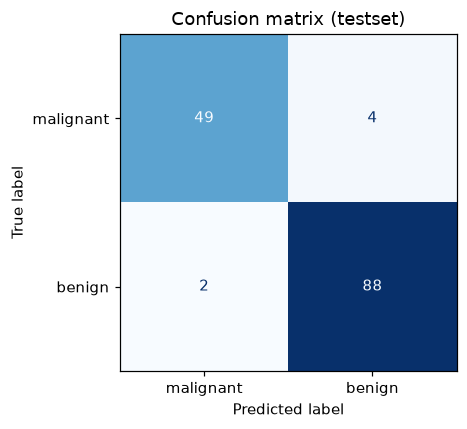

In [7]:
# Een confusion matrix maakt concreet WELKE fouten het model maakt.
# In een medische context is de rechterbovenhoek (kwaadaardig gemist!)
# veel erger dan de linkeronderhoek.
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion matrix (testset)")
plt.tight_layout()
plt.show()

In [8]:
# De predictie voor ONZE patiënt.
pred_label = model.predict(X_test.iloc[[i]])[0]
pred_proba = model.predict_proba(X_test.iloc[[i]])[0]

print(f"--- Patiënt {i} volgens het random forest ---")
print(f"Werkelijke diagnose : {class_names[y_test.iloc[i]]}")
print(f"Modelpredictie      : {class_names[pred_label]}")
print(f"Kans op 'benign'    : {pred_proba[1]:.4f}")
print(f"Kans op 'malignant' : {pred_proba[0]:.4f}")
print()
print("De vraag voor de rest van de notebook: WAAROM?")

--- Patiënt 7 volgens het random forest ---
Werkelijke diagnose : malignant
Modelpredictie      : malignant
Kans op 'benign'    : 0.0579
Kans op 'malignant' : 0.9421

De vraag voor de rest van de notebook: WAAROM?


### 2.1 Eerste (naïeve) poging: de ingebouwde feature importance

`model.feature_importances_` geeft de **mean decrease in impurity** (MDI): hoeveel elke feature
gemiddeld bijdroeg aan het "zuiverder" maken van de splits in de bomen.

Dat is gratis meegeleverd, maar het heeft drie serieuze problemen:

1. **Bias richting features met veel unieke waarden** — continue features winnen bijna altijd van binaire.
2. **Berekend op de trainingsdata** — een feature die het model laat overfitten lijkt belangrijk.
3. **Alleen globaal en zonder richting** — je weet niet of een hoge waarde de predictie *omhoog* of *omlaag* duwt, en al helemaal niet wat er bij één patiënt gebeurde.

Een betere model-agnostische globale maat is **permutation importance**: schud één kolom door elkaar
en meet hoeveel de score daalt. Laten we beide vergelijken.

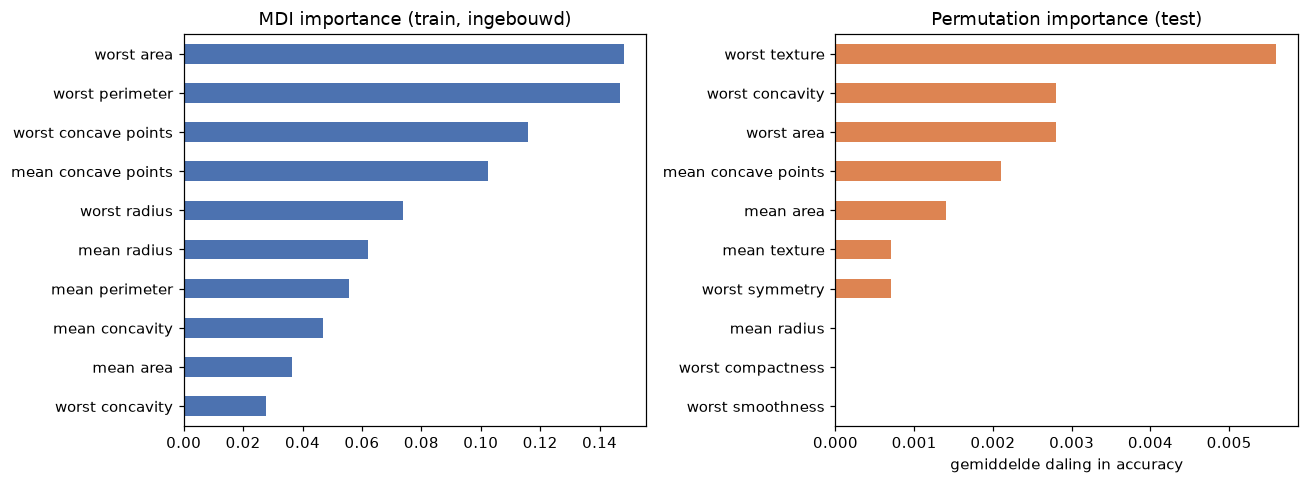

In [9]:
# --- (a) MDI importance: gratis, maar op de TRAINdata en zonder richting ---
mdi = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False)

# --- (b) Permutation importance op de TESTdata: eerlijker ---
# We hussellen elke kolom 10x en meten het gemiddelde verlies aan accuracy.
perm = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
perm_s = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mdi.head(10)[::-1].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("MDI importance (train, ingebouwd)")
perm_s.head(10)[::-1].plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Permutation importance (test)")
axes[1].set_xlabel("gemiddelde daling in accuracy")
plt.tight_layout()
plt.show()

**Observatie voor de klas:** de twee ranglijsten verschillen. Sterk gecorreleerde features
(`mean radius`, `mean perimeter` en `mean area` meten in feite hetzelfde) delen hun belang
en duiken op wisselende plaatsen op.

Maar het grootste bezwaar blijft: dit zegt **niets over patiënt 7**.
Daarvoor hebben we lokale uitleg nodig.

---

# 🟢 Methode 1 — SHAP

## 3.1 Het idee

SHAP staat voor **SHapley Additive exPlanations** (Lundberg & Lee, 2017). Het leent een idee uit
de coöperatieve speltheorie van Lloyd Shapley.

### Het spel

Stel je voor dat de **features samen een spel spelen** en dat de "winst" de predictie is.
De vraag: *hoe verdeel je die winst eerlijk over de spelers?*

De **Shapley-waarde** van feature *i* is de gemiddelde marginale bijdrage van die feature
over **alle mogelijke volgordes** waarin je de features aan het model kunt toevoegen:

$$\phi_i = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\;\bigl[f(S \cup \{i\}) - f(S)\bigr]$$

In gewone taal: *"Wat verandert er aan de predictie als ik feature i toevoeg aan een groep features
die het model al kent — gemiddeld over alle mogelijke groepen?"*

### De drie eigenschappen die dit uniek maken

1. **Efficiëntie (additiviteit)** — de bijdragen tellen exact op tot de predictie:
   $$f(x) = \underbrace{E[f(X)]}_{\text{base value}} + \sum_{i=1}^{M}\phi_i$$
2. **Symmetrie** — twee features die altijd hetzelfde doen, krijgen dezelfde waarde.
3. **Dummy** — een feature die de predictie nooit verandert, krijgt exact 0.

Shapley bewees dat dit de **enige** verdeling is die aan deze eigenschappen voldoet. Dat is de reden
dat SHAP als "de" theoretisch correcte methode geldt.

### De prijs: rekenkracht

Alle deelverzamelingen doorlopen betekent $2^{M}$ combinaties — bij 30 features al ruim een miljard.
Daarom bestaan er *explainers* die dit benaderen of exact-maar-snel uitrekenen:

| Explainer | Voor welk model | Snelheid |
|---|---|---|
| `TreeExplainer` | bomen, random forest, XGBoost, LightGBM | exact & snel (polynomiaal) |
| `LinearExplainer` | lineaire modellen | triviaal |
| `KernelExplainer` | **elk** model (model-agnostisch) | traag, benadering |
| `DeepExplainer` / `GradientExplainer` | neurale netwerken | middelmatig |

Wij hebben een random forest → `TreeExplainer`. 🎉

> **Misverstand om weg te nemen:** een SHAP-waarde is **geen** causaal effect en
> **geen** "hoe belangrijk is deze feature". Het is: *hoeveel duwde deze featurewaarde de
> predictie weg van het gemiddelde, voor deze ene rij.*

## 3.2 De explainer opzetten

In [10]:
# De explainer krijgt het GETRAINDE model. Voor bomen heeft hij geen
# achtergronddataset nodig: de boomstructuur bevat al alle informatie
# over hoe vaak welke paden gevolgd worden.
explainer = shap.TreeExplainer(model)

# De explainer aanroepen op data geeft een 'Explanation'-object terug.
# Dat bundelt drie dingen: de SHAP-waarden, de originele featurewaarden
# en de base value. Alle shap.plots.* functies kunnen daar meteen mee overweg.
shap_exp = explainer(X_test)

print("Type          :", type(shap_exp).__name__)
print("values.shape  :", shap_exp.values.shape)
print()
print("Lees dat als (aantal rijen, aantal features, aantal klassen).")

Type          : Explanation
values.shape  : (143, 30, 2)

Lees dat als (aantal rijen, aantal features, aantal klassen).


### Even opletten: de derde dimensie

Voor een **binaire classifier** geeft `TreeExplainer` waarden voor *beide* klassen:
shape `(n_rijen, 30 features, 2 klassen)`. De twee lagen zijn elkaars spiegelbeeld
(ze tellen samen op tot 0), want de kansen tellen op tot 1.

We kiezen consequent **klasse 1 = `benign` (goedaardig)** — ook bij LIME en IG straks.
Een **positieve** waarde betekent dan: *deze featurewaarde duwt de predictie richting "goedaardig"*.
Een **negatieve** waarde duwt richting "kwaadaardig".

In [11]:
# Slice de laatste as: alle rijen, alle features, klasse-index 1.
shap_benign = shap_exp[:, :, 1]

print("Vorm na slicing :", shap_benign.values.shape)
print(f"Base value      : {shap_benign.base_values[0]:.4f}")
print()
print("De base value is de gemiddelde voorspelling van het model over de trainingsdata:")
print(f"  aandeel 'benign' in de trainset = {y_train.mean():.4f}")
print("Dat is het VERTREKPUNT van elke uitleg: zonder enige feature te kennen,")
print("zou het model deze kans voorspellen.")

Vorm na slicing : (143, 30)
Base value      : 0.6260

De base value is de gemiddelde voorspelling van het model over de trainingsdata:
  aandeel 'benign' in de trainset = 0.6268
Dat is het VERTREKPUNT van elke uitleg: zonder enige feature te kennen,
zou het model deze kans voorspellen.


## 3.3 Globale uitleg — SHAP-waarden aggregeren

Een SHAP-waarde is lokaal, maar als je het **gemiddelde van de absolute waarden** neemt over
alle testrijen, krijg je een globale importance die wél consistent is:

$$\text{importance}_i = \frac{1}{n}\sum_{j=1}^{n} |\phi_i^{(j)}|$$

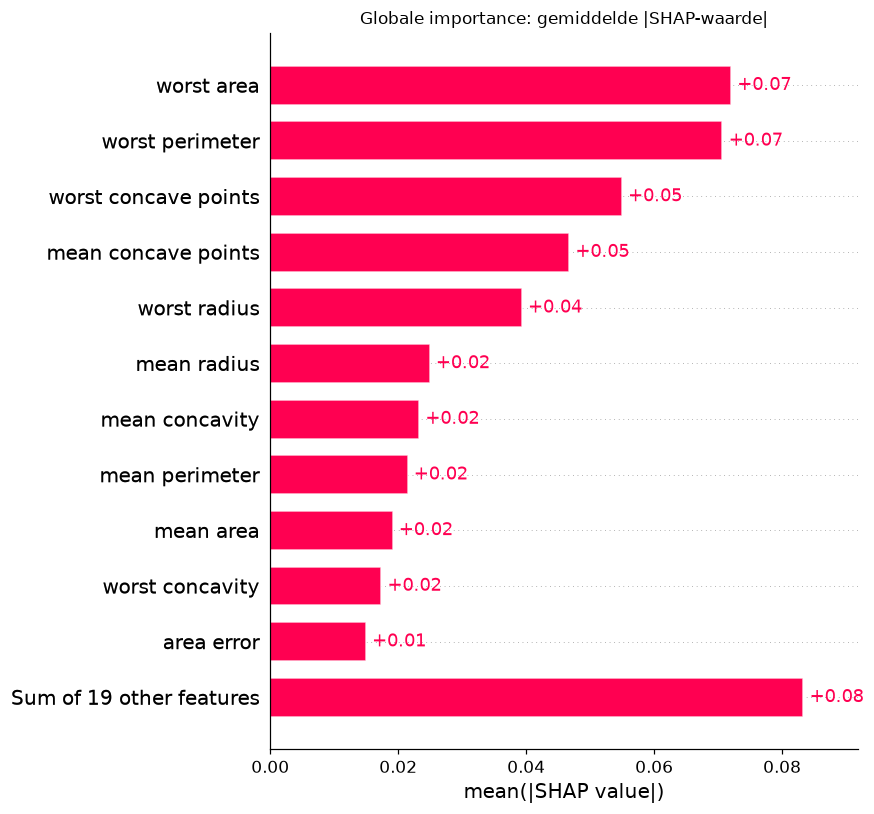

In [12]:
# De bar plot doet precies die aggregatie: gemiddelde |SHAP| per feature.
shap.plots.bar(shap_benign, max_display=12, show=False)
plt.title("Globale importance: gemiddelde |SHAP-waarde|", fontsize=11)
plt.tight_layout()
plt.show()

### De beeswarm: de rijkste plot uit de hele SHAP-bibliotheek

Neem hier de tijd voor met je studenten. Elke **stip is één patiënt uit de testset**:

- **Verticale as**: de features, gesorteerd op belangrijkheid (belangrijkste bovenaan).
- **Horizontale positie**: de SHAP-waarde. Rechts = duwt richting *goedaardig*, links = richting *kwaadaardig*.
- **Kleur**: de **waarde van de feature zelf**. Rood = hoge waarde, blauw = lage waarde.
- **Dikte van de zwerm**: hoeveel patiënten er op die plek zitten.

Het patroon dat je zoekt: *"rood links, blauw rechts"* betekent dat een **hoge**
featurewaarde de predictie richting **kwaadaardig** duwt — een negatief verband dus.

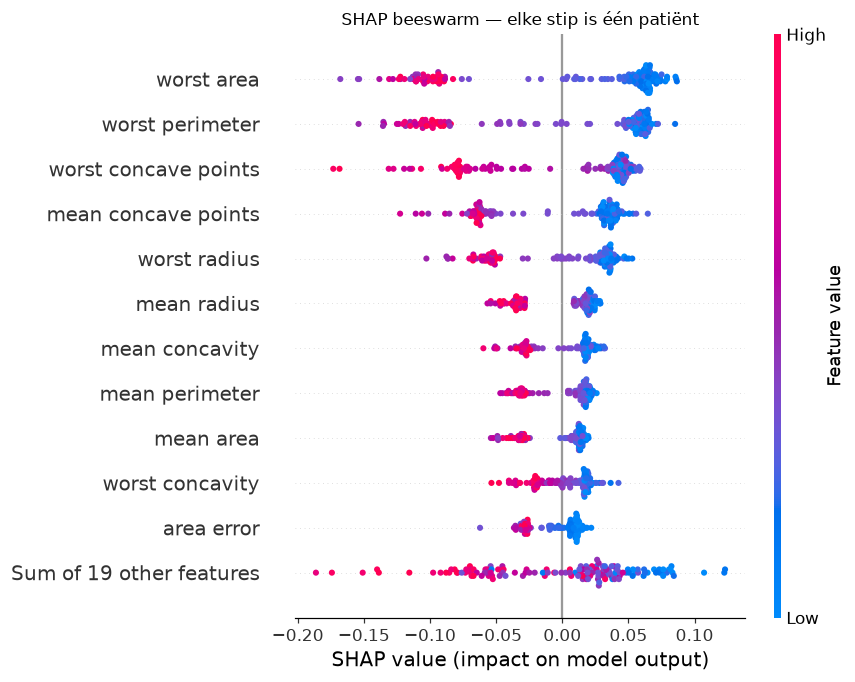

In [13]:
shap.plots.beeswarm(shap_benign, max_display=12, show=False)
plt.title("SHAP beeswarm — elke stip is één patiënt", fontsize=11)
plt.tight_layout()
plt.show()

**Te bespreken in de les:** kijk naar `worst concave points` en `worst perimeter`.
De rode stippen (hoge waarden) liggen links, de blauwe rechts. Medisch gezien klopt dat:
grote tumoren met veel concave randen zijn verdachter. Het model heeft dus iets geleerd dat
een patholoog herkent — precies het soort *sanity check* waarvoor je XAI gebruikt.

## 3.4 Lokale uitleg — patiënt 7 ontleed

### De waterfall plot

Dit is *de* plot om aan een niet-technisch publiek te tonen. Je leest hem van onder naar boven:

- Onderaan start je bij $E[f(X)]$, de **base value**: wat het model zou gokken zonder enige info.
- Elke balk is één feature die de predictie verschuift (rood = omhoog duwen, blauw = omlaag).
- Bovenaan kom je uit op $f(x)$: de uiteindelijke voorspelde kans voor **deze** patiënt.

De features die het minst bijdragen worden onderaan samengevat als "n other features".

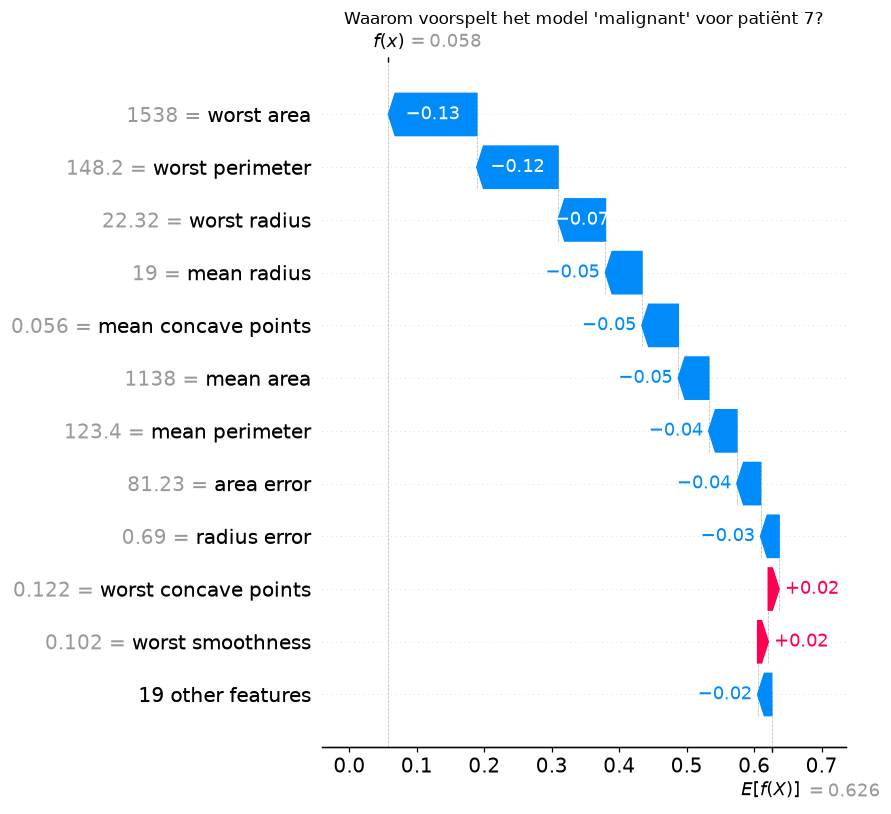

In [14]:
# shap_benign[i] selecteert de uitleg van één rij -> een Explanation van 1 instantie.
shap.plots.waterfall(shap_benign[i], max_display=12, show=False)
plt.title(f"Waarom voorspelt het model '{class_names[pred_label]}' voor patiënt {i}?",
          fontsize=11)
plt.tight_layout()
plt.show()

In [15]:
# Dezelfde informatie als een leesbare tabel: de 10 sterkste bijdragen,
# gesorteerd op absolute grootte. Dit is vaak nuttiger dan een plot
# als je de uitleg in een rapport of een applicatie moet gieten.
shap_tabel = (
    pd.DataFrame({
        "featurewaarde": X_test.iloc[i].values,
        "shap_waarde": shap_benign.values[i],
    }, index=feature_names)
    .assign(richting=lambda d: np.where(d.shap_waarde > 0, "-> benign", "-> malignant"))
    .reindex(pd.Series(np.abs(shap_benign.values[i]), index=feature_names)
             .sort_values(ascending=False).index)
    .head(10)
    .round(4)
)
display(shap_tabel)

,featurewaarde,shap_waarde,richting
worst area,1538.0000,-0.1309,-> malignant
worst perimeter,148.2000,-0.1204,-> malignant
worst radius,22.3200,-0.0703,-> malignant
mean radius,19.0000,-0.0541,-> malignant
mean concave points,0.0563,-0.0539,-> malignant
mean area,1138.0000,-0.0451,-> malignant
mean perimeter,123.4000,-0.0417,-> malignant
area error,81.2300,-0.0351,-> malignant
radius error,0.6896,-0.0274,-> malignant
worst concave points,0.1218,0.0160,-> benign


### De force plot: dezelfde uitleg, horizontaal

De force plot toont de bijdragen als krachten die tegen elkaar in duwen. Handig als je
meerdere patiënten naast elkaar wil tonen.

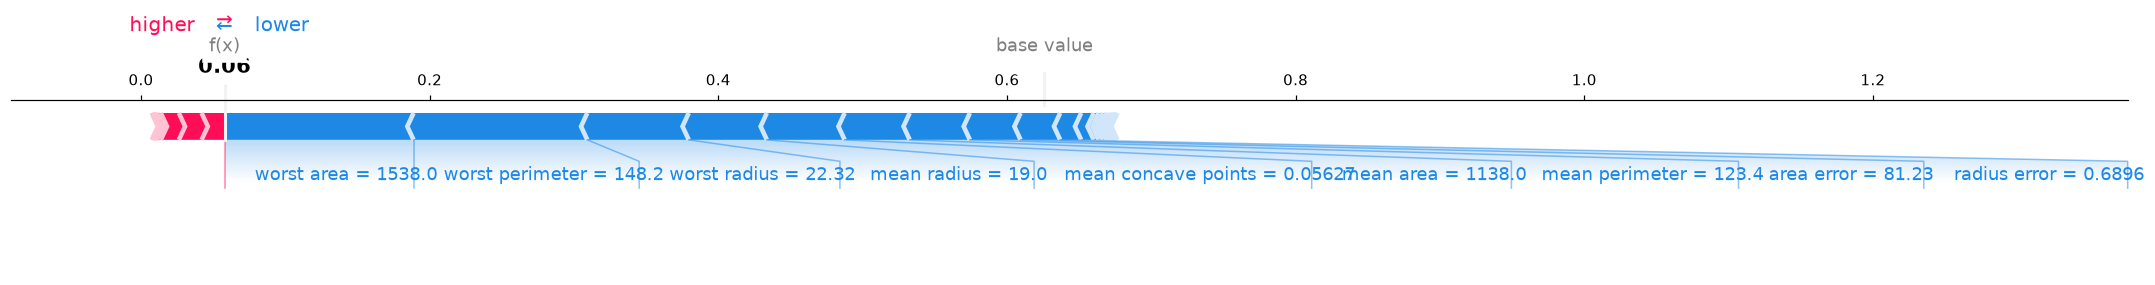

In [16]:
# matplotlib=True rendert een statische figuur. (Zonder die parameter krijg je
# een interactieve JavaScript-versie; die vereist shap.initjs() en werkt niet
# in elke notebook-viewer, dus voor lesmateriaal is de statische versie veiliger.)
shap.plots.force(shap_benign[i], matplotlib=True, show=False, figsize=(20, 3))
plt.tight_layout()
plt.show()

## 3.5 De rekening controleren: het efficiëntie-axioma

Dit is het overtuigendste moment van de les. We rekenen de belofte van SHAP na:

$$\text{base value} + \sum_i \phi_i = f(x)$$

Als dit klopt tot op machineprecisie, dan is de uitleg geen benadering maar een **exacte
decompositie** van wat het model deed.

In [17]:
base      = shap_benign.base_values[i]                    # E[f(X)]
bijdragen = shap_benign.values[i]                         # de 30 SHAP-waarden phi_i
som       = base + bijdragen.sum()                        # de reconstructie
echt      = model.predict_proba(X_test.iloc[[i]])[0, 1]   # wat het model echt zegt

print(f"base value (E[f(X)])        : {base: .6f}")
print(f"som van alle SHAP-waarden   : {bijdragen.sum(): .6f}")
print(f"                              {'-'*12}")
print(f"base + som                  : {som: .6f}")
print(f"werkelijke modelpredictie   : {echt: .6f}")
print(f"verschil                    : {abs(som - echt): .2e}")

# assert laat de notebook falen als de bewering niet klopt -
# een nette manier om een claim in lesmateriaal 'live' te bewijzen.
assert np.isclose(som, echt, atol=1e-6), "Additiviteit geschonden!"
print()
print("✅ De uitleg telt exact op tot de predictie. Dat is de efficiëntie-eigenschap.")

base value (E[f(X)])        :  0.625978
som van alle SHAP-waarden   : -0.568034
                              ------------
base + som                  :  0.057944
werkelijke modelpredictie   :  0.057944
verschil                    :  1.09e-15

✅ De uitleg telt exact op tot de predictie. Dat is de efficiëntie-eigenschap.


### Bonus: een dependence plot

Een scatterplot van *featurewaarde* tegen *SHAP-waarde* toont de vorm van het verband dat het
model geleerd heeft — inclusief niet-lineariteiten en drempelwaarden die je in een
lineair model nooit zou zien. De kleur toont een tweede feature, waardoor **interacties**
zichtbaar worden.

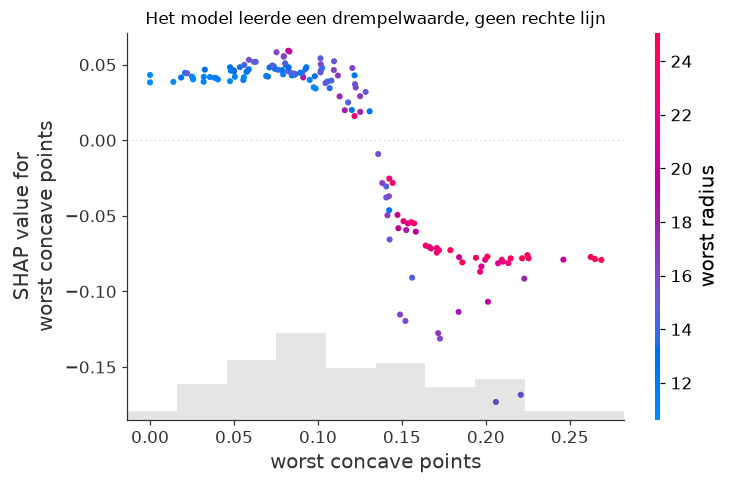

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
shap.plots.scatter(
    shap_benign[:, "worst concave points"],   # x-as: deze feature
    color=shap_benign[:, "worst radius"],     # kleur: interactie met deze feature
    ax=ax, show=False,
)
ax.set_title("Het model leerde een drempelwaarde, geen rechte lijn", fontsize=11)
plt.tight_layout()
plt.show()

**Te bespreken:** zie je de scherpe knik? Onder een bepaalde waarde van `worst concave points`
is de bijdrage sterk positief (goedaardig), erboven kantelt hij naar negatief. Zo'n **stapfunctie**
is typisch voor boommodellen. Een logistische regressie zou hier een rechte lijn hebben getrokken
en de drempel gemist hebben.

> 🔑 **Onthoud voor straks:** een random forest is een **stapfunctie**. De afgeleide is overal nul
> of ongedefinieerd. Dat is exact de reden waarom methode 3 (Integrated Gradients) een
> **ander model** nodig heeft.

---

# 🟠 Methode 2 — LIME

## 4.1 Het idee

LIME = **Local Interpretable Model-agnostic Explanations** (Ribeiro, Singh & Guestrin, 2016).

> *Een complexe beslissingsgrens is globaal krom, maar als je ver genoeg inzoomt op één punt,
> is hij bijna recht.*

Dus: benader het black-box model **in de buurt van één instantie** met een simpel,
leesbaar model (meestal een lineaire regressie). De coëfficiënten van dat simpele model
zijn je uitleg.

### Het recept, stap voor stap

1. Neem de instantie $x$ die je wil verklaren.
2. **Genereer perturbaties**: duizenden nieuwe, licht gewijzigde rijen rond $x$
   (LIME sampelt uit de verdeling van de trainingsdata).
3. **Label ze met het black-box model**: vraag aan het echte model wat het voorspelt
   voor elke perturbatie. *Het model wordt hier als orakel gebruikt — vandaar
   "model-agnostisch": LIME hoeft niet te weten wat erin zit.*
4. **Weeg** elke perturbatie op basis van hoe dicht ze bij $x$ ligt
   (een exponentiële kernel: dichtbij = zwaar, veraf = licht).
5. **Train een gewogen lineaire regressie** (ridge) op die gelabelde perturbaties.
6. De **coëfficiënten** van dat lineaire model zijn de uitleg.

Formeel minimaliseert LIME:

$$\xi(x) = \underset{g \in G}{\arg\min}\; \underbrace{\mathcal{L}(f, g, \pi_x)}_{\text{lokale getrouwheid}} + \underbrace{\Omega(g)}_{\text{complexiteit van de uitleg}}$$

waarbij $f$ het black-box model is, $g$ het simpele model, $\pi_x$ de nabijheidskernel
en $\Omega$ een strafterm die de uitleg kort houdt (bv. maximaal 10 features).

### Discretisatie: waarom LIME "worst radius > 18.79" zegt

Voor tabulaire data **discretiseert** LIME continue features standaard in kwartielen. De uitleg
wordt daardoor een set **regels** ("`worst area > 1084`") in plaats van kale getallen.
Dat leest veel prettiger voor een leek, maar let op: de uitleg gaat dan over een
*interval*, niet over de exacte waarde.

> **Belangrijkste verschil met SHAP:** LIME heeft **geen axioma**. Niets garandeert dat de
> gewichten optellen tot de predictie. Wat je wél krijgt is een R², die meet hoe goed de
> rechte lijn het model lokaal benadert. Die R² is dus een **kwaliteitscontrole op de uitleg zelf**.

## 4.2 De explainer opzetten

In [19]:
# De LIME-explainer wordt gebouwd op de TRAININGSDATA. Hij heeft die nodig om
# te weten hoe hij realistische perturbaties moet genereren (gemiddelde en
# standaardafwijking per feature, en de kwartielgrenzen voor de discretisatie).
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,        # LIME wil numpy, geen DataFrame
    feature_names=feature_names,         # zodat de uitleg leesbaar is
    class_names=class_names,             # ['malignant', 'benign']
    mode="classification",
    discretize_continuous=True,          # -> regels i.p.v. kale getallen (zie hierboven)
    random_state=RANDOM_STATE,           # LIME is stochastisch: seed = reproduceerbaar
)

# LIME roept ons model aan met een kale numpy-array, terwijl het model getraind is
# op een DataFrame MET kolomnamen. Zonder dit wrappertje krijg je bij elke aanroep
# een sklearn-waarschuwing. Meteen een goede gewoonte: maak de predict-functie
# expliciet in plaats van model.predict_proba rechtstreeks door te geven.
def voorspel_kans(rijen):
    return model.predict_proba(pd.DataFrame(rijen, columns=feature_names))

print("LIME-explainer klaar.")
print(f"Gebouwd op {X_train.shape[0]} trainingsrijen en {len(feature_names)} features.")

LIME-explainer klaar.
Gebouwd op 426 trainingsrijen en 30 features.


## 4.3 Globale uitleg — die bestaat niet

Dit is geen vergetelheid van de bibliotheek: **LIME is per constructie puur lokaal**.
Er is geen aggregatie die zinvol is, want elke uitleg komt uit een ander lokaal model
met een andere discretisatie. Wil je een globaal beeld, gebruik dan SHAP (§3.3) of
permutation importance (§2.1).

*(Er bestaat wel `SP-LIME`, dat een handvol representatieve instanties selecteert om
samen een globaal beeld te geven, maar dat is iets anders dan een echte globale importance.)*

## 4.4 Lokale uitleg — patiënt 7 ontleed

In [20]:
# Nu verklaren we DEZELFDE patiënt i als bij SHAP.
#
# Belangrijke parameters:
#   data_row      : de instantie die je wil verklaren (1D numpy array)
#   predict_fn    : een functie die KANSEN teruggeeft (niet model.predict!) ->
#                   LIME heeft een continue output nodig om op te regresseren
#   num_features  : hoeveel features mag de uitleg bevatten (de Omega-strafterm)
#   num_samples   : hoeveel perturbaties genereren. Meer = stabieler maar trager.
#   labels        : voor welke klasse(n) we uitleg willen -> (1,) = 'benign'
lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[i].values,
    predict_fn=voorspel_kans,
    num_features=10,
    num_samples=5000,
    labels=(1,),
)

print(f"Uitleg gegenereerd voor patiënt {i}, richting klasse '{class_names[1]}'.")

Uitleg gegenereerd voor patiënt 7, richting klasse 'benign'.


In [21]:
# as_list() geeft de uitleg als (regel, gewicht)-paren.
# Positief gewicht = duwt richting 'benign' (klasse 1), negatief = richting 'malignant'.
print(f"LIME-uitleg voor patiënt {i} — richting klasse '{class_names[1]}':")
print()
for regel, gewicht in lime_exp.as_list(label=1):
    pijl = "-> benign   " if gewicht > 0 else "-> malignant"
    print(f"  {gewicht:+7.4f}  {pijl}  {regel}")

LIME-uitleg voor patiënt 7 — richting klasse 'benign':

  -0.1489  -> malignant  worst area > 1034.25
  -0.1267  -> malignant  worst perimeter > 124.97
  -0.0975  -> malignant  worst radius > 18.55
  -0.0485  -> malignant  mean area > 765.38
  -0.0454  -> malignant  area error > 45.13
  -0.0364  -> malignant  mean radius > 15.75
  -0.0277  -> malignant  mean perimeter > 103.67
  -0.0276  -> malignant  radius error > 0.47
  +0.0202  -> benign     worst smoothness <= 0.12
  +0.0174  -> benign     mean smoothness <= 0.09


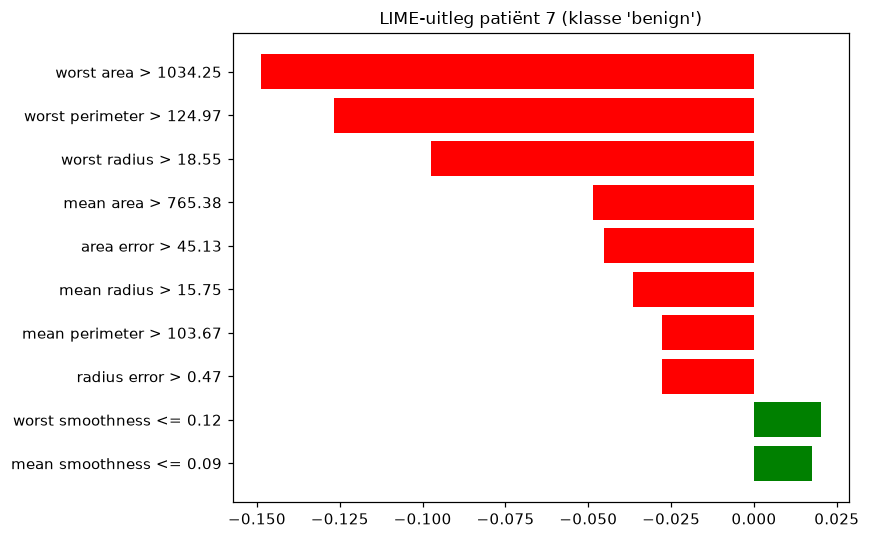

In [22]:
# LIME's eigen plotfunctie. Groen = richting de verklaarde klasse (benign),
# rood = ertegenin.
fig = lime_exp.as_pyplot_figure(label=1)
fig.set_size_inches(8, 5)
plt.title(f"LIME-uitleg patiënt {i} (klasse '{class_names[1]}')", fontsize=11)
plt.tight_layout()
plt.show()

## 4.5 De rekening controleren: lokale getrouwheid (R²)

SHAP had een axioma; LIME heeft dat niet. Wat LIME wél geeft, is de **R² van het lokale
surrogaatmodel**: hoe goed benadert de rechte lijn het echte model in de buurt van deze patiënt?

Dit getal is minstens zo belangrijk als de uitleg zelf. **Is de R² laag, dan mag je de uitleg
niet vertrouwen** — het model is daar simpelweg te grillig om door een rechte lijn te worden
samengevat.

In [23]:
print(f"R² van het lokale surrogaat           : {lime_exp.score:.4f}")
print(f"Voorspelling van het lokale surrogaat : {lime_exp.local_pred[0]:.4f}")
print(f"Voorspelling van het ECHTE model      : {pred_proba[1]:.4f}")
print(f"Afwijking                             : {abs(lime_exp.local_pred[0] - pred_proba[1]):.4f}")
print()
print("Vergelijk met SHAP hierboven, waar het verschil in de orde van 1e-15 lag.")
print("LIME benadert; SHAP (bij bomen) decomponeert exact. Dat is het fundamentele verschil.")

R² van het lokale surrogaat           : 0.4797
Voorspelling van het lokale surrogaat : 0.1883
Voorspelling van het ECHTE model      : 0.0579
Afwijking                             : 0.1304

Vergelijk met SHAP hierboven, waar het verschil in de orde van 1e-15 lag.
LIME benadert; SHAP (bij bomen) decomponeert exact. Dat is het fundamentele verschil.


**Interpretatie van dit resultaat:** de R² ligt hier rond de 0.5 en het surrogaat voorspelt een
merkbaar andere kans dan het echte model. Dat is géén fout in de code — het is een **eerlijk
signaal** dat het random forest rond deze patiënt sterk niet-lineair is (herinner je de
stapfunctie uit §3.5). De *richting* van de uitleg blijft bruikbaar, de *exacte getallen* niet.

Dit is precies het soort nuance dat studenten moeten meenemen: een uitlegmethode die altijd
een mooi plaatje produceert, produceert niet altijd een geldige uitleg.

### LIME is stochastisch — laat dat zien

SHAP geeft bij bomen altijd exact hetzelfde antwoord. LIME niet: het trekt willekeurige
perturbaties, dus twee runs geven licht verschillende gewichten. Dat is geen bug, dat is
de methode. Maar je studenten moeten dat weten vóór ze een LIME-uitleg aan een klant tonen.

We draaien de uitleg drie keer **zonder vaste seed** en vergelijken.

In [24]:
# Een nieuwe explainer ZONDER random_state, zodat elke run anders sampelt.
onstabiel = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
)

runs = {}
for r in range(3):
    e = onstabiel.explain_instance(
        X_test.iloc[i].values, voorspel_kans,
        num_features=8,
        num_samples=1000,   # bewust weinig samples -> meer ruis
        labels=(1,),
    )
    runs[f"run {r+1}"] = dict(e.as_list(label=1))

vergelijk = pd.DataFrame(runs).round(4)
print("Zelfde patiënt, drie LIME-runs met num_samples=1000:")
display(vergelijk)
print("Merk op: de gewichten verschillen, en soms verschijnt/verdwijnt een regel volledig.")
print("Verhoog num_samples (bv. 5000) en zet random_state -> veel stabieler.")

Zelfde patiënt, drie LIME-runs met num_samples=1000:


,run 1,run 2,run 3
worst area > 1034.25,-0.1459,-0.1636,-0.1559
worst perimeter > 124.97,-0.1278,-0.1361,-0.1206
worst radius > 18.55,-0.0940,-0.0854,-0.0879
area error > 45.13,-0.0539,-0.0515,-0.0513
mean area > 765.38,-0.0455,-0.0294,-0.0462
mean radius > 15.75,-0.0421,-0.0362,-0.0448
perimeter error > 3.28,-0.0381,NaN,-0.0310
mean smoothness <= 0.09,0.0329,NaN,NaN
mean perimeter > 103.67,NaN,-0.0481,NaN
18.82 < mean texture <= 21.80,NaN,-0.0298,NaN


Merk op: de gewichten verschillen, en soms verschijnt/verdwijnt een regel volledig.
Verhoog num_samples (bv. 5000) en zet random_state -> veel stabieler.


---

# 🔵 Methode 3 — Integrated Gradients

## 5.1 Het idee

**Integrated Gradients** (Sundararajan, Taly & Yan, 2017) komt uit de deep-learning-hoek en is
vandaag de standaardmethode voor neurale netwerken.

### Waarom niet gewoon de gradiënt?

De gradiënt $\partial f / \partial x_i$ lijkt de natuurlijke maat voor "hoe gevoelig is de output
voor deze feature". Maar de kale gradiënt heeft een fataal probleem: **saturatie**.

Stel dat het netwerk al volledig overtuigd is ("kans = 0.999"). Dan is de functie daar vlak,
de gradiënt is bijna nul, en je zou concluderen dat *geen enkele* feature belangrijk is —
terwijl het netwerk juist keihard overtuigd is. De gradiënt meet de helling in één punt,
niet de afgelegde weg.

### De oplossing: integreer over een pad

IG kiest een **baseline** $x'$ (een "neutrale" input, bv. de gemiddelde patiënt) en loopt
in een rechte lijn van die baseline naar de echte input $x$. Onderweg wordt de gradiënt
opgeteld:

$$IG_i(x) = \underbrace{(x_i - x'_i)}_{\text{hoe ver reisde deze feature}} \times \underbrace{\int_{\alpha=0}^{1} \frac{\partial f\bigl(x' + \alpha (x - x')\bigr)}{\partial x_i} \, d\alpha}_{\text{gemiddelde gevoeligheid onderweg}}$$

In de praktijk wordt die integraal benaderd met een Riemann-som over `n_steps` tussenpunten
(meestal 50–300).

### Het completeness-axioma

Net als SHAP heeft IG een optelgarantie, hier **completeness** genoemd:

$$\sum_{i=1}^{M} IG_i(x) = f(x) - f(x')$$

*De attributies tellen op tot het verschil tussen de predictie en de baseline-predictie.*
Vergelijk met SHAP: daar was het referentiepunt $E[f(X)]$, hier is het één gekozen baseline $x'$.
**Dat is de kern van het verschil tussen beide methodes.**

### De baseline is een ontwerpkeuze, geen detail

Je uitleg is altijd "ten opzichte van de baseline". Kies je slecht, dan is je uitleg zinloos.
Gangbare keuzes:

| Baseline | Betekenis van de uitleg |
|---|---|
| Nulvector op geschaalde data | "t.o.v. de gemiddelde patiënt" ← *wij gebruiken deze* |
| Een echte gezonde controlepatiënt | "t.o.v. deze specifieke referentiepersoon" |
| Gemiddelde over veel baselines | ≈ *Expected Gradients* — dat is in feite SHAP (zie §5.5) |

### En het model?

IG heeft **gradiënten** nodig, dus een differentieerbaar model. Ons random forest is een
stapfunctie (§3.5) met afgeleide nul — daar valt niets te integreren. We trainen dus een klein
**neuraal netwerk op exact dezelfde dataset** en verklaren daarmee dezelfde patiënt.

## 5.1b IG uitgetekend

De formule hierboven is compact, maar het idee erachter is heel visueel. Drie beelden en je
snapt het voorgoed.

### Het beeld: een wandeling in de bergen

> Je vertrekt bij de **baseline** (de gemiddelde patiënt) en wandelt in een **rechte lijn** naar
> **jouw patiënt**. Onderweg verandert de voorspelling van het model — dat is je hoogteverschil.
> IG verdeelt dat totale hoogteverschil over de **richtingen** waarin je gewandeld hebt,
> dus over de features.

```
   voorspelling
        ▲
 f(x')  ┤ ●  baseline: "gemiddelde patiënt"   kans op benign = 0.67
        │  ╲
        │   ╲        ← onderweg meten we voortdurend de helling
        │    ╲          (= de gradiënt) per feature
        │     ╲___
 f(x)   ┤         ●  patiënt 7                kans op benign = 0.00
        └─────────────────────────────────────▶
          α=0                              α=1

   totaal hoogteverschil  f(x) − f(x')  =  −0.67
   IG verdeelt die −0.67 over de 30 features.   ← completeness
```

Dat is meteen het verschil met SHAP samengevat: **SHAP verdeelt het verschil met het
gemiddelde van álle data, IG verdeelt het verschil met één gekozen vertrekpunt.**

### Beeld 1 — waarom de kale gradiënt faalt (saturatie)

We nemen een speelgoedmodel met **één** feature, zodat we alles kunnen tekenen.
Links zie je de modelfunctie, rechts zijn helling (de gradiënt).

Let op de raaklijn in het eindpunt: die is bijna **vlak**. Wie alleen naar de gradiënt in het punt
zelf kijkt, concludeert "deze feature doet niets" — terwijl de feature het model juist van 0.05
naar 0.99 heeft geduwd. **De gradiënt meet de helling in één punt; IG meet de afgelegde weg.**

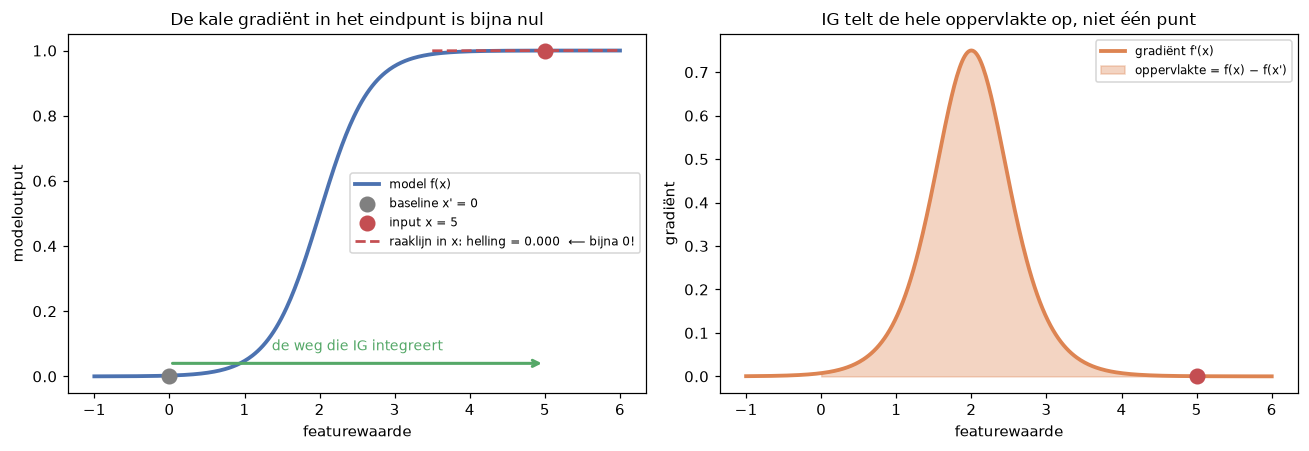

oppervlakte onder de gradiënt : 0.997404
f(x) - f(x')                  : 0.997404

Dat is completeness in zijn eenvoudigste vorm: de integraal van de afgeleide
over het pad is precies het hoogteverschil. IG doet dit per feature.


In [25]:
# Speelgoedmodel met 1 feature: een sigmoïde die satureert.
def f_speelgoed(x):
    return 1 / (1 + np.exp(-3 * (x - 2)))

def helling(x):                       # de analytische afgeleide
    return 3 * f_speelgoed(x) * (1 - f_speelgoed(x))

x_baseline, x_input = 0.0, 5.0        # vertrekpunt en onze "patiënt"
xs = np.linspace(-1, 6, 400)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))

# --- links: de modelfunctie + raaklijnen ---
a1.plot(xs, f_speelgoed(xs), lw=2.5, color="#4C72B0", label="model f(x)")
a1.scatter([x_baseline], [f_speelgoed(x_baseline)], s=90, zorder=5,
           color="grey", label=f"baseline x' = {x_baseline:.0f}")
a1.scatter([x_input], [f_speelgoed(x_input)], s=90, zorder=5,
           color="#C44E52", label=f"input x = {x_input:.0f}")

# De raaklijn IN het inputpunt: bijna horizontaal -> dit is de saturatie.
t = np.linspace(3.5, 6, 10)
a1.plot(t, f_speelgoed(x_input) + helling(x_input) * (t - x_input),
        "--", color="#C44E52", lw=1.8,
        label=f"raaklijn in x: helling = {helling(x_input):.3f}  ⟵ bijna 0!")

a1.annotate("", xy=(x_input, 0.04), xytext=(x_baseline, 0.04),
            arrowprops=dict(arrowstyle="->", lw=2, color="#55A868"))
a1.text((x_baseline + x_input) / 2, 0.08, "de weg die IG integreert",
        ha="center", color="#55A868", fontsize=9)
a1.set_xlabel("featurewaarde"); a1.set_ylabel("modeloutput")
a1.set_title("De kale gradiënt in het eindpunt is bijna nul", fontsize=11)
a1.legend(fontsize=8, loc="center right")

# --- rechts: de gradiënt, met de oppervlakte eronder ---
pad = np.linspace(x_baseline, x_input, 400)
a2.plot(xs, helling(xs), lw=2.5, color="#DD8452", label="gradiënt f'(x)")
a2.fill_between(pad, helling(pad), alpha=0.35, color="#DD8452",
                label="oppervlakte = f(x) − f(x')")
a2.scatter([x_input], [helling(x_input)], s=90, color="#C44E52", zorder=5)
a2.set_xlabel("featurewaarde"); a2.set_ylabel("gradiënt")
a2.set_title("IG telt de hele oppervlakte op, niet één punt", fontsize=11)
a2.legend(fontsize=8)

plt.tight_layout()
plt.show()

# En de completeness in dit speelgeval, numeriek:
oppervlakte = np.trapezoid(helling(pad), pad)
print(f"oppervlakte onder de gradiënt : {oppervlakte:.6f}")
print(f"f(x) - f(x')                  : {f_speelgoed(x_input) - f_speelgoed(x_baseline):.6f}")
print()
print("Dat is completeness in zijn eenvoudigste vorm: de integraal van de afgeleide")
print("over het pad is precies het hoogteverschil. IG doet dit per feature.")

### Beeld 2 — het pad in twee dimensies

Met twee features wordt het pad zichtbaar als een **rechte lijn door de featureruimte**.
De achtergrondkleur is de voorspelling van het model; de pijltjes zijn de gradiënten
die IG onderweg opmeet.

Elk pijltje wijst de richting van de steilste stijging. IG projecteert die pijltjes op de
wandelrichting en telt ze op — apart voor de horizontale (feature 1) en de verticale
(feature 2) component.

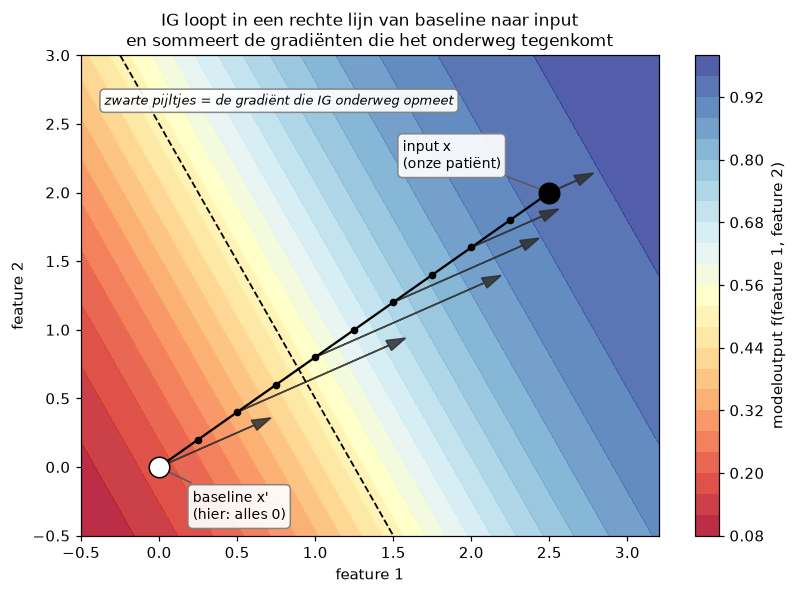

In [26]:
# Speelgoedmodel met 2 features. Feature 1 weegt zwaarder dan feature 2.
# Feature 1 heeft gewicht 1.2, feature 2 gewicht 0.6: het model is dus
# twee keer zo gevoelig voor feature 1.
def f2(u, v):
    return 1 / (1 + np.exp(-(1.2 * u + 0.6 * v - 1.5)))

def grad_f2(u, v):                     # de partiële afgeleiden
    s = f2(u, v)
    return np.array([1.2 * s * (1 - s), 0.6 * s * (1 - s)])

p_base  = np.array([0.0, 0.0])         # baseline
p_input = np.array([2.5, 2.0])         # onze "patiënt"

# Achtergrond: de modeloutput over de hele ruimte.
uu, vv = np.meshgrid(np.linspace(-0.5, 3.2, 220), np.linspace(-0.5, 3.0, 220))
zz = f2(uu, vv)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
cs = ax.contourf(uu, vv, zz, levels=25, cmap="RdYlBu", alpha=0.85)
plt.colorbar(cs, ax=ax, label="modeloutput f(feature 1, feature 2)")
ax.contour(uu, vv, zz, levels=[0.5], colors="black", linewidths=1.2, linestyles="--")

# Het rechte pad van baseline naar input, met 11 tussenpunten.
alphas = np.linspace(0, 1, 11)
pad_punten = p_base + alphas[:, None] * (p_input - p_base)
ax.plot(pad_punten[:, 0], pad_punten[:, 1], "-o", color="black", ms=4, lw=1.5)

# Op elk tussenpunt de gradiënt tekenen.
for p in pad_punten[::2]:
    g = grad_f2(*p)
    ax.arrow(p[0], p[1], g[0] * 4.0, g[1] * 4.0,      # 4.0 = enkel om ze zichtbaar te maken
             head_width=0.08, color="#2E2E2E", alpha=0.85, length_includes_head=True)

ax.scatter(*p_base,  s=180, color="white", edgecolor="black", zorder=6)
ax.scatter(*p_input, s=180, color="black", zorder=6)

# Labels krijgen een wit kaartje, anders lopen ze door de contourkleuren heen.
kaartje = dict(boxstyle="round,pad=0.35", fc="white", ec="0.5", alpha=0.92)
ax.annotate("baseline x'\n(hier: alles 0)", p_base, textcoords="offset points",
            xytext=(22, -34), fontsize=9, bbox=kaartje,
            arrowprops=dict(arrowstyle="->", color="0.35"))
ax.annotate("input x\n(onze patiënt)", p_input, textcoords="offset points",
            xytext=(-96, 16), fontsize=9, bbox=kaartje,
            arrowprops=dict(arrowstyle="->", color="0.35"))
ax.text(-0.35, 2.72, "zwarte pijltjes = de gradiënt die IG onderweg opmeet",
        fontsize=8.5, style="italic", va="top", bbox=kaartje)
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
ax.set_title("IG loopt in een rechte lijn van baseline naar input\n"
             "en sommeert de gradiënten die het onderweg tegenkomt", fontsize=11)
plt.tight_layout()
plt.show()

### Beeld 3 — en zo wordt het verschil verdeeld

Nu de laatste stap. Voor elk van de twee features:

$$IG_i = \underbrace{(x_i - x'_i)}_{\text{afgelegde afstand in richting } i} \times \underbrace{\overline{\text{gradiënt}_i}}_{\text{gemiddelde helling onderweg}}$$

En de twee resultaten samen moeten precies het hoogteverschil $f(x) - f(x')$ opleveren.

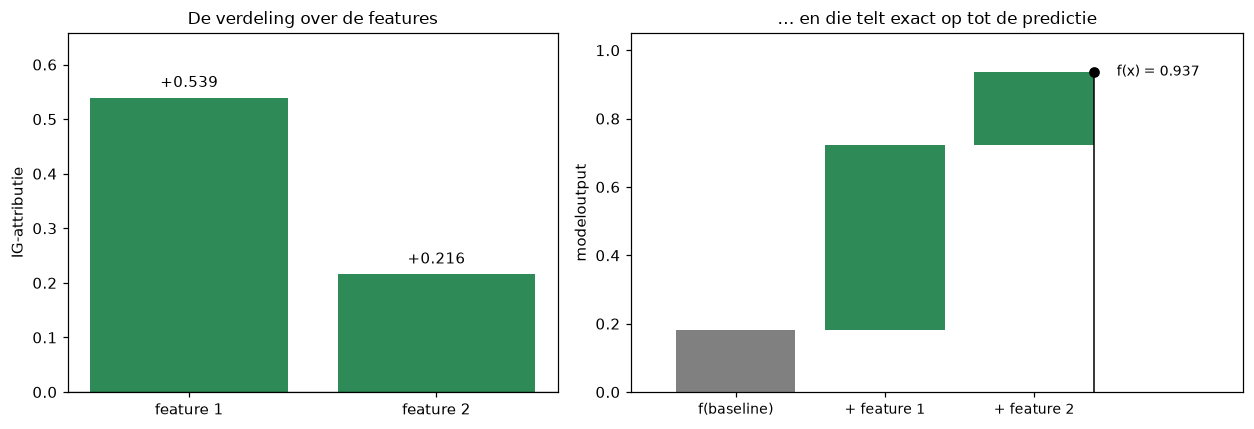

IG feature 1        : +0.538997
IG feature 2        : +0.215599
                      ------------
som                 : +0.754596
f(x) - f(baseline)  : +0.754601

Feature 1 krijgt meer krediet dan feature 2, om twee redenen tegelijk:
hij reisde verder (2.5 vs 2.0) EN het model is er gevoeliger voor (gewicht 1.2 vs 0.6).
Precies die twee factoren zijn de twee helften van de IG-formule.


In [27]:
# IG voor het 2D-speelgoedmodel, met de trapeziumregel. Geen torch nodig:
# we hebben de afgeleide hier analytisch.
n_steps = 200
alphas = np.linspace(0, 1, n_steps)
punten = p_base + alphas[:, None] * (p_input - p_base)
G = np.array([grad_f2(*p) for p in punten])            # (n_steps, 2)

gem_gradient = (G[:-1] + G[1:]).mean(axis=0) / 2       # trapeziumregel
ig_speelgoed = (p_input - p_base) * gem_gradient       # de IG-attributies

f_in, f_bs = f2(*p_input), f2(*p_base)

fig, (b1, b2) = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1, 1.25]})

# Links: de twee attributies als balken.
b1.bar(["feature 1", "feature 2"], ig_speelgoed,
       color=["#2E8B57" if w > 0 else "#C44E52" for w in ig_speelgoed])
b1.axhline(0, color="black", lw=0.8)
for k, w in enumerate(ig_speelgoed):
    b1.text(k, w + 0.02, f"{w:+.3f}", ha="center", fontsize=10)
b1.set_ylim(0, max(ig_speelgoed) * 1.22)          # ruimte voor de labels bovenaan
b1.set_ylabel("IG-attributie")
b1.set_title("De verdeling over de features", fontsize=11)

# Rechts: de optelsom (waterfall).
niveaus = [f_bs, f_bs + ig_speelgoed[0], f_bs + ig_speelgoed.sum()]
labels  = ["f(baseline)", "+ feature 1", "+ feature 2"]
b2.bar(range(3), [f_bs, ig_speelgoed[0], ig_speelgoed[1]],
       bottom=[0, f_bs, niveaus[1]],
       color=["grey", "#2E8B57", "#2E8B57"])
b2.plot([2.4, 2.4], [0, f_in], color="black", lw=1)
b2.scatter([2.4], [f_in], color="black", zorder=5)
b2.text(2.5, f_in, f"  f(x) = {f_in:.3f}", va="center", fontsize=9)
b2.set_xticks(range(3)); b2.set_xticklabels(labels, fontsize=9)
b2.set_xlim(-0.7, 3.4)                            # ruimte voor het f(x)-label rechts
b2.set_ylim(0, 1.05)
b2.set_ylabel("modeloutput")
b2.set_title("… en die telt exact op tot de predictie", fontsize=11)

plt.tight_layout()
plt.show()

print(f"IG feature 1        : {ig_speelgoed[0]:+.6f}")
print(f"IG feature 2        : {ig_speelgoed[1]:+.6f}")
print(f"                      {'-'*12}")
print(f"som                 : {ig_speelgoed.sum():+.6f}")
print(f"f(x) - f(baseline)  : {f_in - f_bs:+.6f}")
print()
print("Feature 1 krijgt meer krediet dan feature 2, om twee redenen tegelijk:")
print("hij reisde verder (2.5 vs 2.0) EN het model is er gevoeliger voor (gewicht 1.2 vs 0.6).")
print("Precies die twee factoren zijn de twee helften van de IG-formule.")

### De drie beelden samengevat

| Beeld | Wat je moet onthouden |
|---|---|
| 1 — saturatie | De gradiënt in het punt zelf liegt. Je moet de **hele weg** vanaf een referentiepunt optellen. |
| 2 — het pad | Dat pad is een **rechte lijn** van baseline naar input; onderweg meet je telkens de gradiënt. |
| 3 — de verdeling | Elke feature krijgt *afgelegde afstand × gemiddelde gevoeligheid*, en samen tellen ze op tot $f(x) - f(x')$. |

Nu we weten wat we doen, passen we het toe op de echte dataset.

## 5.2 De explainer opzetten

Eerst het model. Let op: neurale netwerken hebben **geschaalde** input nodig, anders domineert
`mean area` (waarden rond 650) alle andere features. We fitten de `StandardScaler`
op de trainset en passen hem toe op beide sets.

In [28]:
# --- (a) Schalen: fit op TRAIN, transform op beide (nooit fitten op test!) ---
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

# --- (b) Een klein netwerk: 30 -> 32 -> 16 -> 2 ---
torch.manual_seed(RANDOM_STATE)
netwerk = nn.Sequential(
    nn.Linear(30, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 2),          # 2 logits: [malignant, benign]
)

# --- (c) Trainen: full-batch, 300 epochs. De dataset is klein genoeg. ---
optimizer = torch.optim.Adam(netwerk.parameters(), lr=1e-3, weight_decay=1e-4)
verliesfunctie = nn.CrossEntropyLoss()

Xt = torch.tensor(X_train_s, dtype=torch.float32)
yt = torch.tensor(y_train.values, dtype=torch.long)

for epoch in range(300):
    optimizer.zero_grad()
    verlies = verliesfunctie(netwerk(Xt), yt)
    verlies.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"epoch {epoch:3d}  verlies {verlies.item():.4f}")

netwerk.eval()   # eval-modus: schakelt dropout/batchnorm uit. Altijd doen voor uitleg!

# --- (d) Evalueren, zodat we kunnen vergelijken met het random forest ---
with torch.no_grad():
    nn_proba_test = torch.softmax(netwerk(torch.tensor(X_test_s, dtype=torch.float32)), dim=1).numpy()

print()
print(f"Netwerk  — accuracy {accuracy_score(y_test, nn_proba_test.argmax(1)):.3f}, "
      f"AUC {roc_auc_score(y_test, nn_proba_test[:, 1]):.3f}")
print(f"Forest   — accuracy {accuracy_score(y_test, y_pred):.3f}, "
      f"AUC {roc_auc_score(y_test, y_proba):.3f}")
print()
print("Twee heel verschillende modellen, vergelijkbare prestaties. Ideaal om te vergelijken:")
print("als beide modellen dezelfde features gebruiken, is dat een sterk signaal.")

epoch   0  verlies 0.7158
epoch 100  verlies 0.0829
epoch 200  verlies 0.0400

Netwerk  — accuracy 0.965, AUC 0.997
Forest   — accuracy 0.958, AUC 0.994

Twee heel verschillende modellen, vergelijkbare prestaties. Ideaal om te vergelijken:
als beide modellen dezelfde features gebruiken, is dat een sterk signaal.


In [29]:
# IG verklaart een SCALAIRE output. Ons netwerk geeft logits; die zijn niet
# vergelijkbaar met de kansen van SHAP/LIME. We wikkelen het netwerk daarom in
# een module die softmax-KANSEN teruggeeft, net als predict_proba.
class KansModel(nn.Module):
    def __init__(self, basis):
        super().__init__()
        self.basis = basis
    def forward(self, x):
        return torch.softmax(self.basis(x), dim=1)

kansmodel = KansModel(netwerk).eval()

# De input van onze patiënt, als tensor met batch-dimensie (1, 30).
x_patient = torch.tensor(X_test_s[i:i+1], dtype=torch.float32)

# DE BASELINE: een nulvector. Omdat de data gestandaardiseerd is, betekent
# "alles nul" letterlijk "een patiënt met voor elke feature de gemiddelde waarde".
baseline = torch.zeros_like(x_patient)

with torch.no_grad():
    f_x    = kansmodel(x_patient)[0, 1].item()   # f(x)
    f_base = kansmodel(baseline)[0, 1].item()    # f(x')

print(f"f(x)        = {f_x:.6f}   <- kans op 'benign' voor patiënt {i}")
print(f"f(baseline) = {f_base:.6f}   <- kans voor de 'gemiddelde patiënt'")
print(f"te verklaren verschil = {f_x - f_base:+.6f}")
print()
print("Dat verschil is exact wat IG straks over de 30 features moet verdelen.")

# De explainer zelf: één regel.
ig = IntegratedGradients(kansmodel)
print()
print("IntegratedGradients-explainer klaar.")

f(x)        = 0.000018   <- kans op 'benign' voor patiënt 7
f(baseline) = 0.667651   <- kans voor de 'gemiddelde patiënt'
te verklaren verschil = -0.667633

Dat verschil is exact wat IG straks over de 30 features moet verdelen.

IntegratedGradients-explainer klaar.


### Even zelf uitrekenen: IG in 10 regels

Voor je `captum` vertrouwt, is het leerzaam om de formule één keer letterlijk uit te schrijven.
Dit is het hele algoritme: loop over `n_steps` punten tussen baseline en input, bereken de
gradiënt, middel ze, vermenigvuldig met de afgelegde afstand.

In [30]:
def integrated_gradients_zelfgemaakt(x, x_baseline, model, klasse=1, n_steps=200):
    # 1. De alpha's: n_steps punten tussen 0 (baseline) en 1 (de echte input).
    alphas = torch.linspace(0, 1, n_steps)

    gradienten = []
    for alpha in alphas:
        # 2. Een punt op het rechte pad van baseline naar input.
        pad_punt = (x_baseline + alpha * (x - x_baseline)).clone().requires_grad_(True)

        # 3. De output voor de klasse die we verklaren.
        output = model(pad_punt)[0, klasse]

        # 4. De gradiënt van die output t.o.v. de input -> autograd doet het werk.
        grad, = torch.autograd.grad(output, pad_punt)
        gradienten.append(grad)

    G = torch.stack(gradienten)                 # shape: (n_steps, 1, 30)

    # 5. De integraal benaderen met de trapeziumregel (nauwkeuriger dan een
    #    gewoon gemiddelde, vooral bij weinig stappen).
    gemiddelde_gradient = (G[:-1] + G[1:]).mean(dim=0) / 2

    # 6. Vermenigvuldigen met (x - baseline): "hoe ver reisde deze feature".
    return ((x - x_baseline) * gemiddelde_gradient).detach().numpy()[0]


ig_zelf = integrated_gradients_zelfgemaakt(x_patient, baseline, kansmodel, klasse=1, n_steps=200)
print(f"Zelfgemaakte IG berekend voor {len(ig_zelf)} features.")
print(f"Som van de attributies: {ig_zelf.sum():+.6f}")
print(f"f(x) - f(baseline)    : {f_x - f_base:+.6f}")

Zelfgemaakte IG berekend voor 30 features.
Som van de attributies: -0.669221
f(x) - f(baseline)    : -0.667633


In [31]:
# En nu hetzelfde met captum, in één aanroep.
#   target=1                     -> we verklaren de kans op 'benign'
#   n_steps=200                  -> aantal punten op het pad
#   return_convergence_delta     -> geeft meteen de fout op het completeness-axioma
ig_captum_t, delta = ig.attribute(
    x_patient,
    baselines=baseline,
    target=1,
    n_steps=200,
    return_convergence_delta=True,
)
ig_captum = ig_captum_t.detach().numpy()[0]

print(f"captum IG som         : {ig_captum.sum():+.6f}")
print(f"zelfgemaakte IG som   : {ig_zelf.sum():+.6f}")
print(f"grootste verschil per feature tussen beide: {np.abs(ig_captum - ig_zelf).max():.2e}")
print()
print("✅ Onze 10 regels doen exact hetzelfde als de bibliotheek.")

captum IG som         : -0.666713
zelfgemaakte IG som   : -0.669221
grootste verschil per feature tussen beide: 6.00e-04

✅ Onze 10 regels doen exact hetzelfde als de bibliotheek.


## 5.3 Globale uitleg — IG aggregeren

Net als bij SHAP kun je lokale attributies middelen om een globaal beeld te krijgen:
$\frac{1}{n}\sum_j |IG_i^{(j)}|$. Captum verwerkt de hele testset in één keer.

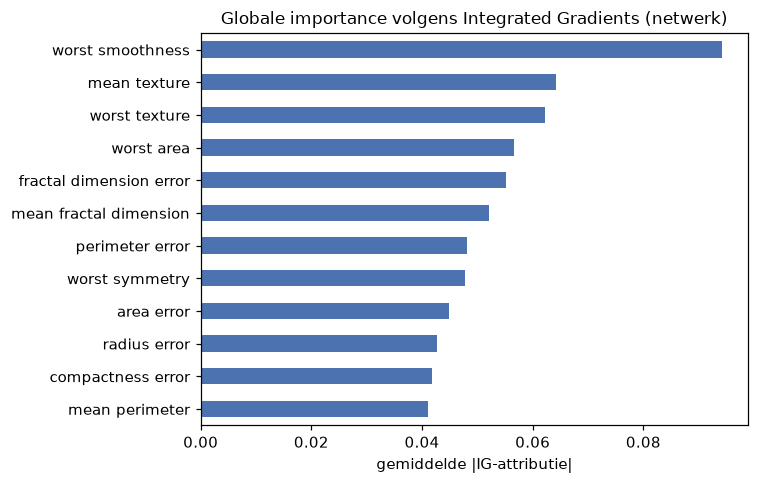

In [32]:
# Alle testrijen tegelijk. n_steps mag lager voor een globaal overzicht.
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
ig_alle = ig.attribute(
    X_test_t,
    baselines=torch.zeros_like(X_test_t),
    target=1,
    n_steps=50,
).detach().numpy()

ig_globaal = pd.Series(np.abs(ig_alle).mean(axis=0), index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ig_globaal.head(12)[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Globale importance volgens Integrated Gradients (netwerk)", fontsize=11)
ax.set_xlabel("gemiddelde |IG-attributie|")
plt.tight_layout()
plt.show()

## 5.4 Lokale uitleg — patiënt 7 ontleed

### Eerst het pad zichtbaar maken

Deze plot bestaat in geen enkele bibliotheek, maar hij legt IG in één beeld uit.
We volgen de voorspelling van het netwerk terwijl we van de baseline ($\alpha=0$)
naar onze patiënt ($\alpha=1$) wandelen. **IG is letterlijk de oppervlakte onder de
helling van deze curve, per feature uitgesplitst.**

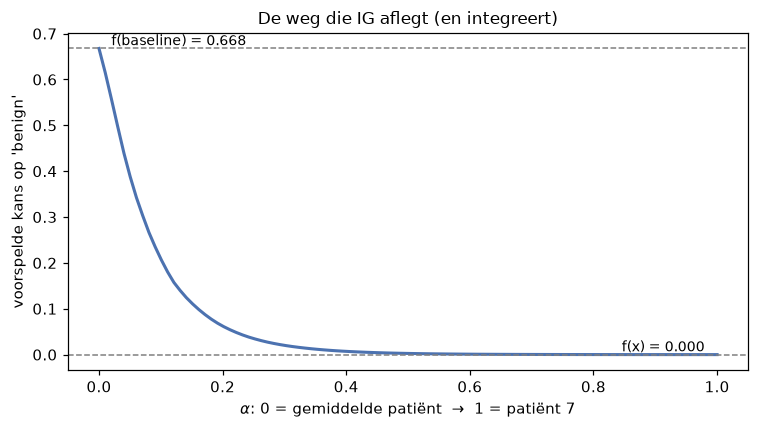

Zie je hoe steil de curve in het begin daalt en daarna afvlakt?
Dat afvlakken IS de saturatie uit §5.1. Een kale gradiënt bij alpha=1 zou
bijna nul zijn en je wijsmaken dat niets belangrijk was. IG telt de hele weg op.


In [33]:
alphas = torch.linspace(0, 1, 100)
with torch.no_grad():
    pad = baseline + alphas.view(-1, 1) * (x_patient - baseline)   # (100, 30)
    curve = kansmodel(pad)[:, 1].numpy()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas.numpy(), curve, lw=2, color="#4C72B0")
ax.axhline(f_base, ls="--", c="grey", lw=1)
ax.axhline(f_x, ls="--", c="grey", lw=1)
ax.annotate(f"f(baseline) = {f_base:.3f}", (0.02, f_base), va="bottom", fontsize=9)
ax.annotate(f"f(x) = {f_x:.3f}", (0.98, f_x), va="bottom", ha="right", fontsize=9)
ax.set_xlabel(r"$\alpha$: 0 = gemiddelde patiënt  →  1 = patiënt " + str(i))
ax.set_ylabel("voorspelde kans op 'benign'")
ax.set_title("De weg die IG aflegt (en integreert)", fontsize=11)
plt.tight_layout()
plt.show()

print("Zie je hoe steil de curve in het begin daalt en daarna afvlakt?")
print("Dat afvlakken IS de saturatie uit §5.1. Een kale gradiënt bij alpha=1 zou")
print("bijna nul zijn en je wijsmaken dat niets belangrijk was. IG telt de hele weg op.")

In [34]:
# De attributies als leesbare tabel, gesorteerd op absolute grootte.
ig_reeks = pd.Series(ig_captum, index=feature_names)
ig_tabel = (
    pd.DataFrame({
        "featurewaarde": X_test.iloc[i].values,     # de ORIGINELE, ongeschaalde waarde
        "geschaald": X_test_s[i],                   # wat het netwerk echt zag
        "ig_attributie": ig_captum,
    }, index=feature_names)
    .assign(richting=lambda d: np.where(d.ig_attributie > 0, "-> benign", "-> malignant"))
    .reindex(ig_reeks.abs().sort_values(ascending=False).index)
    .head(10)
    .round(4)
)
display(ig_tabel)

,featurewaarde,geschaald,ig_attributie,richting
worst smoothness,0.1021,-1.3378,0.1745,-> benign
mean fractal dimension,0.0504,-1.7072,-0.1166,-> malignant
worst area,1538.0000,1.1916,-0.1135,-> malignant
mean radius,19.0000,1.4052,-0.0950,-> malignant
perimeter error,5.2160,1.2264,-0.0932,-> malignant
worst perimeter,148.2000,1.2391,-0.0890,-> malignant
mean area,1138.0000,1.4134,-0.0882,-> malignant
mean perimeter,123.4000,1.3167,-0.0872,-> malignant
radius error,0.6896,1.1051,-0.0712,-> malignant
area error,81.2300,1.0189,-0.0699,-> malignant


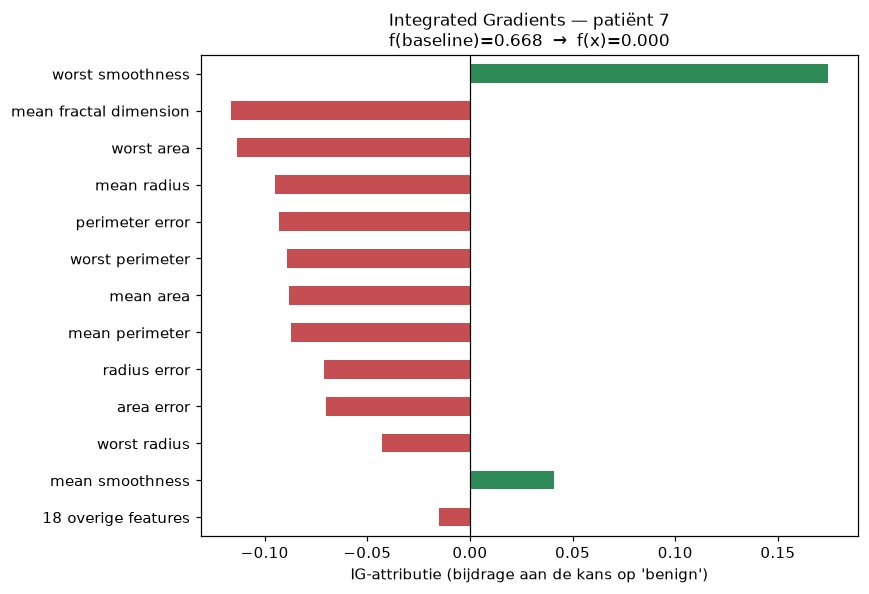

In [35]:
# Een waterfall-achtige plot, zelf gebouwd: van baseline naar predictie.
top = ig_reeks.reindex(ig_reeks.abs().sort_values(ascending=False).index).head(12)
rest = ig_reeks.drop(top.index).sum()
balken = pd.concat([top, pd.Series({f"{len(ig_reeks)-len(top)} overige features": rest})])[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
kleuren = ["#2E8B57" if v > 0 else "#C44E52" for v in balken]
balken.plot.barh(ax=ax, color=kleuren)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("IG-attributie (bijdrage aan de kans op 'benign')")
ax.set_title(f"Integrated Gradients — patiënt {i}\n"
             f"f(baseline)={f_base:.3f}  →  f(x)={f_x:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

## 5.5 De rekening controleren: het completeness-axioma

$$\sum_i IG_i(x) = f(x) - f(x')$$

Captum geeft ons de fout op dit axioma gratis mee als `delta`. Die is nooit exact nul,
want we benaderen een integraal met een eindig aantal stappen — maar hij hoort **klein**
te zijn. Is hij groot, verhoog dan `n_steps`.

In [36]:
som_ig = ig_captum.sum()
doel   = f_x - f_base

print(f"som van alle IG-attributies : {som_ig:+.6f}")
print(f"f(x) - f(baseline)          : {doel:+.6f}")
print(f"                              {'-'*12}")
print(f"convergence delta (captum)  : {delta.item():+.2e}")
print(f"relatieve fout              : {abs(som_ig - doel) / abs(doel):.4%}")

assert abs(som_ig - doel) < 0.01, "Completeness geschonden - verhoog n_steps!"
print()
print("✅ De attributies tellen op tot het verschil met de baseline.")
print("   Vergelijk met SHAP (§3.5): daar was het referentiepunt E[f(X)],")
print("   hier is het f(baseline). Zelfde idee, andere nulmeting.")

som van alle IG-attributies : -0.666713
f(x) - f(baseline)          : -0.667633
                              ------------
convergence delta (captum)  : +9.20e-04
relatieve fout              : 0.1378%

✅ De attributies tellen op tot het verschil met de baseline.
   Vergelijk met SHAP (§3.5): daar was het referentiepunt E[f(X)],
   hier is het f(baseline). Zelfde idee, andere nulmeting.


,n_steps,som attributies,|delta|
0,5,-0.718458,0.050825
1,10,-0.656549,0.011084
2,25,-0.664626,0.003007
3,50,-0.660045,0.007589
4,100,-0.666445,0.001188
5,200,-0.666713,0.000920
6,400,-0.668056,0.000422


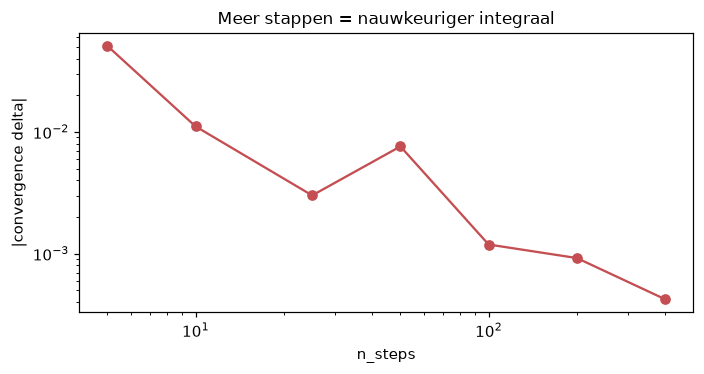

In [37]:
# Hoe snel convergeert die som eigenlijk? Dit toont meteen hoe je n_steps kiest.
resultaten = []
for stappen in [5, 10, 25, 50, 100, 200, 400]:
    a, d = ig.attribute(x_patient, baselines=baseline, target=1,
                        n_steps=stappen, return_convergence_delta=True)
    resultaten.append({"n_steps": stappen,
                       "som attributies": a.sum().item(),
                       "|delta|": abs(d.item())})

conv = pd.DataFrame(resultaten)
display(conv.round(6))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(conv["n_steps"], conv["|delta|"], "o-", color="#C44E52")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n_steps"); ax.set_ylabel("|convergence delta|")
ax.set_title("Meer stappen = nauwkeuriger integraal", fontsize=11)
plt.tight_layout()
plt.show()

### De brug tussen IG en SHAP: Expected Gradients

Een laatste inzicht dat de twee methodes verbindt. Het zwakke punt van IG is de **willekeur
van de baseline**. Wat als je niet één baseline kiest, maar het gemiddelde neemt over veel
baselines uit de trainingsdata?

Dan krijg je **Expected Gradients** — en dat is precies wat `shap.GradientExplainer` doet.
Het resultaat is een SHAP-waarde: de referentie wordt weer $E[f(X)]$ in plaats van één punt.

*IG met een verdeling van baselines ≈ SHAP.* Dat is geen toeval; beide methodes vallen onder
het raamwerk van de additieve attributiemethodes.

Hieronder zetten we beide naast elkaar op **hetzelfde netwerk en dezelfde patiënt**. Let goed op
het resultaat: de uitleg is verwant maar **niet identiek**, en het enige wat verschilt is het
referentiepunt.

In [38]:
# GradientExplainer op HETZELFDE netwerk, met 100 trainingsrijen als achtergrondverdeling.
achtergrond = torch.tensor(X_train_s[:100], dtype=torch.float32)
grad_explainer = shap.GradientExplainer(kansmodel, achtergrond)

sv_nn = grad_explainer.shap_values(x_patient)        # shape (1, 30, 2)
sv_nn_benign = np.array(sv_nn)[0, :, 1]

brug = pd.DataFrame({
    "IG (1 baseline)": ig_captum,
    "ExpGrad (= SHAP, 100 baselines)": sv_nn_benign,
}, index=feature_names)

# Rangcorrelatie over ALLE 30 features (niet enkel de top-10: daar is de
# spreiding kunstmatig klein en zakt elke correlatie vanzelf).
rho    = brug.corr(method="spearman").iloc[0, 1]
tekens = (np.sign(brug.iloc[:, 0]) == np.sign(brug.iloc[:, 1])).mean()

display(brug.reindex(brug["IG (1 baseline)"].abs()
                     .sort_values(ascending=False).index).head(10).round(4))

print(f"Spearman-rangcorrelatie over alle 30 features : {rho:.3f}")
print(f"Aandeel features met hetzelfde teken          : {tekens:.0%}")
print()
print("Interpretatie: zelfde model, zelfde patiënt, en toch geen identieke uitleg.")
print("De rangorde komt grotendeels overeen en de meeste features duwen dezelfde")
print("kant op, maar niet allemaal. Het enige verschil tussen beide kolommen is")
print("het referentiepunt: één vaste baseline versus een verdeling van 100 baselines.")
print("Dat is dus geen detail - het is een ontwerpkeuze die je uitleg mee bepaalt.")

,IG (1 baseline),"ExpGrad (= SHAP, 100 baselines)"
worst smoothness,0.1745,0.0579
mean fractal dimension,-0.1166,-0.0585
worst area,-0.1135,-0.1053
mean radius,-0.0950,-0.0728
perimeter error,-0.0932,-0.0793
worst perimeter,-0.0890,-0.0823
mean area,-0.0882,-0.0753
mean perimeter,-0.0872,-0.0693
radius error,-0.0712,-0.0657
area error,-0.0699,-0.0682


Spearman-rangcorrelatie over alle 30 features : 0.832
Aandeel features met hetzelfde teken          : 80%

Interpretatie: zelfde model, zelfde patiënt, en toch geen identieke uitleg.
De rangorde komt grotendeels overeen en de meeste features duwen dezelfde
kant op, maar niet allemaal. Het enige verschil tussen beide kolommen is
het referentiepunt: één vaste baseline versus een verdeling van 100 baselines.
Dat is dus geen detail - het is een ontwerpkeuze die je uitleg mee bepaalt.


---

# 📊 6. De drie uitleggen naast elkaar

Nu de vergelijking waar het in de les om draait: dezelfde dataset, dezelfde patiënt,
drie methodes.

### Lees dit eerst, vóór je naar de getallen kijkt

1. **De schalen zijn niet vergelijkbaar.**
   - Een SHAP-waarde is een stuk van de kans (telt op tot $f(x) - E[f(X)]$).
   - Een LIME-gewicht is een regressiecoëfficiënt van het lokale surrogaat.
   - Een IG-attributie is een stuk van de kans (telt op tot $f(x) - f(\text{baseline})$).

   Vergelijk dus **rangorde en teken**, niet de absolute grootte. Daarom normaliseren we
   hieronder elke methode naar een *relatief aandeel* $|v_i| / \sum_j |v_j|$.

2. **SHAP en LIME verklaren het random forest; IG verklaart het neurale netwerk.**
   Dat is geen slordigheid maar een noodzakelijkheid (§5.1). Het maakt de vergelijking juist
   interessanter: als drie methodes op twee verschillende modellen dezelfde features aanwijzen,
   dan zit dat signaal **in de data**, niet in het model.

In [39]:
# --- SHAP (random forest) ---
shap_reeks = pd.Series(shap_benign.values[i], index=feature_names)

# --- LIME (random forest) ---
# LIME geeft regels als 'worst area > 1084.0'; we halen de featurenaam eruit.
def feature_uit_regel(regel):
    treffers = [f for f in feature_names if f in regel]
    return max(treffers, key=len) if treffers else regel

lime_reeks = pd.Series({feature_uit_regel(r): w for r, w in lime_exp.as_list(label=1)})

# --- IG (neuraal netwerk) --- (ig_reeks bestaat al uit §5.4)

# Alles in één tabel, uitgelijnd op featurenaam.
drieluik = pd.DataFrame({
    "SHAP (forest)": shap_reeks,
    "LIME (forest)": lime_reeks,
    "IG (netwerk)":  ig_reeks,
})

# Relatief aandeel per methode, zodat de kolommen vergelijkbaar worden.
aandeel = drieluik.abs().div(drieluik.abs().sum(), axis=1)

# Sorteer op het gemiddelde aandeel over de drie methodes.
volgorde = aandeel.mean(axis=1).sort_values(ascending=False).index
overzicht = drieluik.loc[volgorde].head(12)

display(overzicht.round(4))

,SHAP (forest),LIME (forest),IG (netwerk)
worst area,-0.1309,-0.1489,-0.1135
worst perimeter,-0.1204,-0.1267,-0.0890
worst radius,-0.0703,-0.0975,-0.0430
mean area,-0.0451,-0.0485,-0.0882
mean radius,-0.0541,-0.0364,-0.0950
worst smoothness,0.0157,0.0202,0.1745
area error,-0.0351,-0.0454,-0.0699
mean perimeter,-0.0417,-0.0277,-0.0872
perimeter error,-0.0146,NaN,-0.0932
radius error,-0.0274,-0.0276,-0.0712


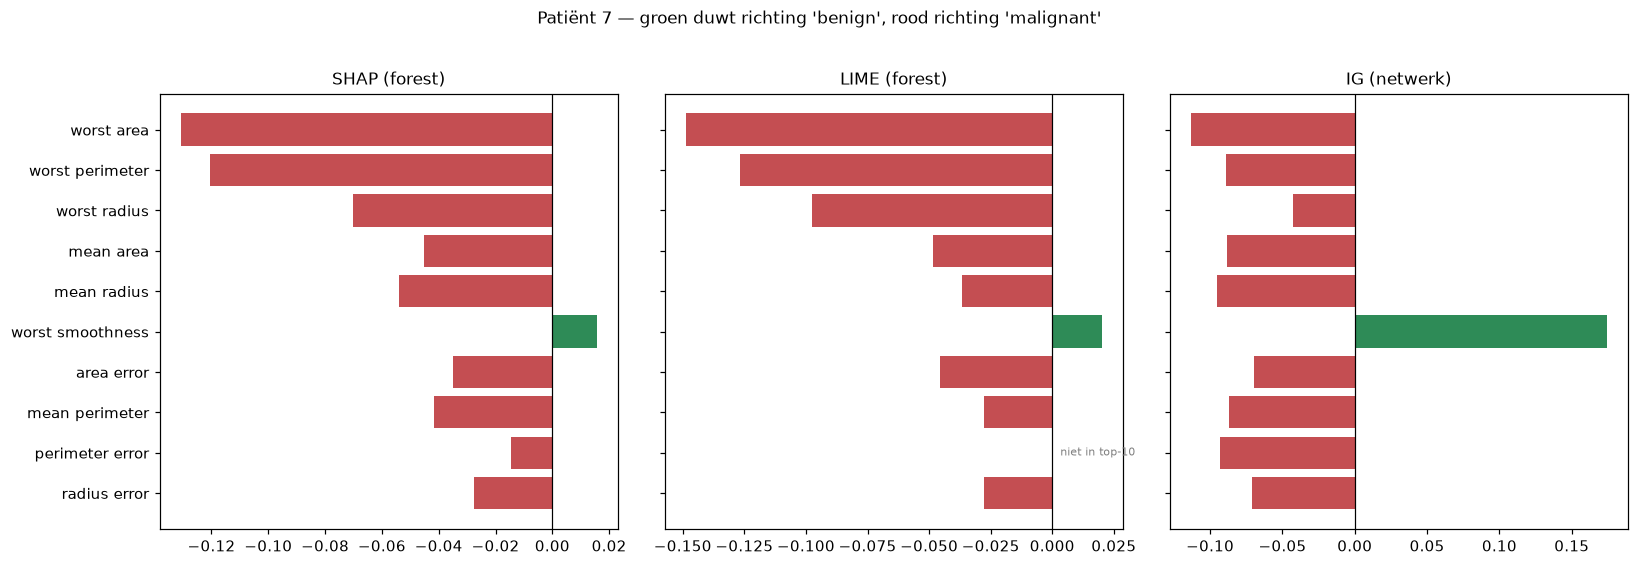

In [40]:
# Drie barplots naast elkaar, elk op zijn eigen schaal maar met dezelfde
# featurevolgorde -> zo zie je in één oogopslag waar ze het eens en oneens zijn.
top_features = list(volgorde[:10])[::-1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
titels = [
    ("SHAP (forest)", "#4C72B0"),
    ("LIME (forest)", "#DD8452"),
    ("IG (netwerk)",  "#55A868"),
]

for ax, (kolom, _) in zip(axes, titels):
    waarden = drieluik.loc[top_features, kolom]
    kleuren = ["#2E8B57" if (v > 0) else "#C44E52" for v in waarden.fillna(0)]
    ax.barh(range(len(top_features)), waarden.fillna(0).values, color=kleuren)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(kolom, fontsize=11)
    # Features die deze methode niet in zijn top-10 had, markeren we.
    for k, f in enumerate(top_features):
        if pd.isna(drieluik.loc[f, kolom]):
            ax.text(0, k, "  niet in top-10", va="center", fontsize=7, color="grey")

fig.suptitle(f"Patiënt {i} — groen duwt richting 'benign', rood richting 'malignant'",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

In [41]:
# Zijn de drie methodes het EENS over de rangorde? Spearman-rangcorrelatie
# op het relatieve aandeel, alleen over features die alle drie de methodes noemen.
gemeenschappelijk = aandeel.dropna()
print(f"Features die alle drie de methodes in beeld hebben: {len(gemeenschappelijk)}")
print()
print("Spearman-rangcorrelatie tussen de methodes:")
display(gemeenschappelijk.corr(method="spearman").round(3))

print()
print("Zijn de TEKENS consistent? (duwen ze dezelfde kant op?)")
tekens = np.sign(drieluik.dropna())
print(f"  SHAP vs LIME : {(tekens['SHAP (forest)'] == tekens['LIME (forest)']).mean():.0%} gelijk")
print(f"  SHAP vs IG   : {(tekens['SHAP (forest)'] == tekens['IG (netwerk)']).mean():.0%} gelijk")
print(f"  LIME vs IG   : {(tekens['LIME (forest)'] == tekens['IG (netwerk)']).mean():.0%} gelijk")

Features die alle drie de methodes in beeld hebben: 10

Spearman-rangcorrelatie tussen de methodes:


,SHAP (forest),LIME (forest),IG (netwerk)
SHAP (forest),1.000,0.939,0.345
LIME (forest),0.939,1.000,0.236
IG (netwerk),0.345,0.236,1.000



Zijn de TEKENS consistent? (duwen ze dezelfde kant op?)
  SHAP vs LIME : 100% gelijk
  SHAP vs IG   : 100% gelijk
  LIME vs IG   : 100% gelijk


## De samenvattende tabel voor je slides

| | **SHAP** | **LIME** | **Integrated Gradients** |
|---|---|---|---|
| **Wat meet het?** | Eerlijke verdeling van de predictie over de features | Coëfficiënten van een lokale lineaire benadering | Opgetelde gevoeligheid langs een pad vanaf een baseline |
| **Referentiepunt** | $E[f(X)]$ (gemiddelde over de data) | geen — puur lokaal | $f(x')$ voor één gekozen baseline |
| **Axioma** | Efficiëntie (exact bij bomen) | geen | Completeness (tot op integratiefout) |
| **Modelvereiste** | geen (sneller bij bomen) | geen | **differentieerbaar** |
| **Deterministisch** | ja (bij bomen) | nee, tenzij seed | ja |
| **Globale uitleg** | ja, door aggregatie | nee | ja, door aggregatie |
| **Snelheid hier** | hele testset < 1 s | ~1 s per instantie | ~ms per instantie |
| **Grootste zwakte** | duur bij niet-boommodellen | geen garanties, instabiel | keuze van de baseline |
| **Typisch domein** | tabulair, tree ensembles | tabulair, tekst, beeld | deep learning: beeld, tekst, tabulair |

### Wie heeft er gelijk?

Ze beantwoorden een subtiel andere vraag:

- **SHAP**: *"Dit is jouw eerlijke aandeel in de predictie, gemiddeld over alle scenario's."*
- **LIME**: *"Dit is de richting waarin het model hier lokaal helt."*
- **IG**: *"Dit is wat er gebeurde onderweg van de gemiddelde patiënt naar jou."*

**De praktische regel:** wijzen twee of drie methodes dezelfde features met hetzelfde teken aan,
dan is je uitleg robuust. **Wijken ze sterk af, dan is dát je belangrijkste bevinding** — het
model is lokaal grillig, of je features zijn sterk gecorreleerd. Gebruik uitlegmethodes dus
zoals je meetinstrumenten gebruikt: **meer dan één**.

---

## 7. Een fout van het model verklaren

De meest leerzame toepassing van XAI: kijk naar een geval waar het model het **fout** had.
Dat legt vaak bloot dat een feature iets anders betekent dan je dacht.

In [42]:
fouten = np.where(y_pred != y_test.values)[0]
print(f"Het random forest maakte {len(fouten)} fout(en) op {len(y_test)} testrijen.")
print("Testset-indices:", fouten)

f = int(fouten[0])
print()
print(f"--- Fout geval: testrij {f} ---")
print(f"Werkelijk : {class_names[y_test.iloc[f]]}")
print(f"Voorspeld : {class_names[y_pred[f]]}  (kans op benign = {y_proba[f]:.3f})")
print()
print("Hoe dicht die kans bij 0.5 ligt, zegt al veel: twijfelde het model, of was het")
print("overtuigd fout? Een overtuigde fout is veel zorgwekkender.")

Het random forest maakte 6 fout(en) op 143 testrijen.
Testset-indices: [  4  44  62  92 118 135]

--- Fout geval: testrij 4 ---
Werkelijk : malignant
Voorspeld : benign  (kans op benign = 0.719)

Hoe dicht die kans bij 0.5 ligt, zegt al veel: twijfelde het model, of was het
overtuigd fout? Een overtuigde fout is veel zorgwekkender.


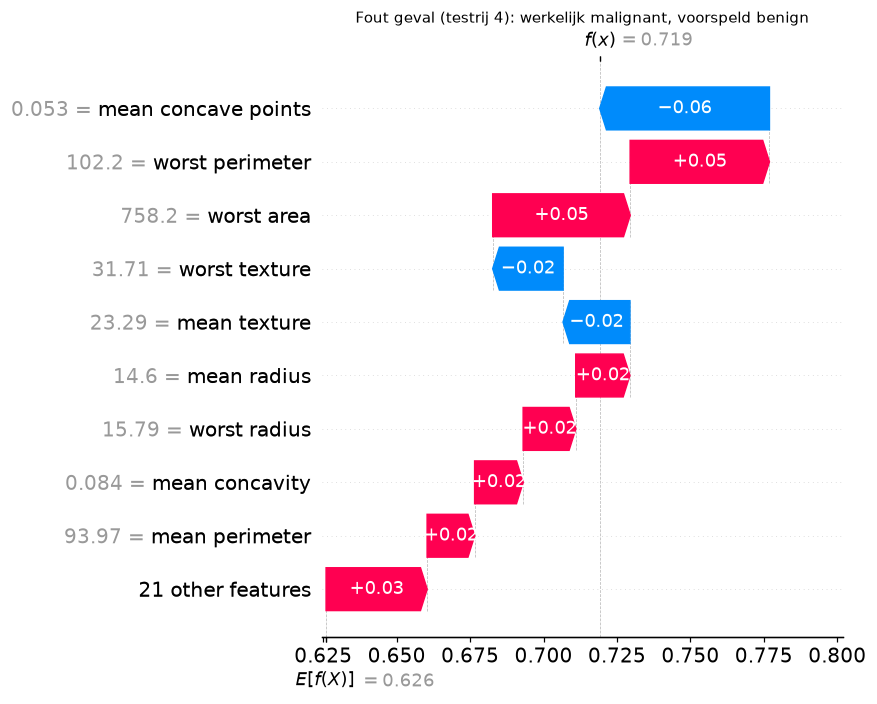

In [43]:
# De waterfall van een fout is didactisch goud: je ziet welke features
# het model in de verkeerde richting duwden.
shap.plots.waterfall(shap_benign[f], max_display=10, show=False)
plt.title(f"Fout geval (testrij {f}): werkelijk {class_names[y_test.iloc[f]]}, "
          f"voorspeld {class_names[y_pred[f]]}", fontsize=10)
plt.tight_layout()
plt.show()

In [44]:
# En wat vond het NETWERK van datzelfde geval? Twee modellen die dezelfde fout
# maken wijst op een moeilijk geval in de data; maken ze verschillende fouten,
# dan is het modelkeuze.
x_fout = torch.tensor(X_test_s[f:f+1], dtype=torch.float32)
ig_fout = ig.attribute(x_fout, baselines=torch.zeros_like(x_fout),
                       target=1, n_steps=200).detach().numpy()[0]

print(f"Random forest : kans op benign = {y_proba[f]:.3f} -> {class_names[y_pred[f]]}")
print(f"Neuraal netwerk: kans op benign = {nn_proba_test[f, 1]:.3f} -> "
      f"{class_names[nn_proba_test[f].argmax()]}")
print(f"Werkelijk      : {class_names[y_test.iloc[f]]}")
print()

vgl_fout = pd.DataFrame({
    "SHAP (forest)": shap_benign.values[f],
    "IG (netwerk)": ig_fout,
}, index=feature_names)
display(vgl_fout.reindex(vgl_fout.abs().mean(axis=1).sort_values(ascending=False).index)
        .head(8).round(4))

Random forest : kans op benign = 0.719 -> benign
Neuraal netwerk: kans op benign = 0.100 -> malignant
Werkelijk      : malignant



,SHAP (forest),IG (netwerk)
mean fractal dimension,-0.0045,-0.3217
mean texture,-0.0227,-0.2923
worst texture,-0.0239,-0.2486
worst symmetry,0.0153,0.1927
mean smoothness,0.0047,0.1178
worst area,0.0468,0.0725
worst fractal dimension,0.0013,0.1056
fractal dimension error,-0.0006,-0.1040


## 8. Valkuilen (bespreek deze expliciet in de les)

1. **Correlatie ≠ causaliteit, en attributie ≠ causaliteit.**
   Een SHAP- of IG-waarde zegt wat het *model* deed, niet wat de *werkelijkheid* doet. Als je model
   heeft geleerd dat "aantal brandweerwagens" een brand voorspelt, zal SHAP dat netjes tonen.
   De uitleg is correct; het model is verkeerd.

2. **Gecorreleerde features verdelen hun krediet.**
   `mean radius`, `mean perimeter` en `mean area` meten hetzelfde. Elk krijgt ongeveer een derde
   van het belang, waardoor ze individueel *onbelangrijk* lijken. Groepeer ze, of gebruik
   `shap.utils.hclust` om de clustering zichtbaar te maken.

3. **Het referentiepunt bepaalt de hele uitleg.**
   Bij SHAP is dat de achtergronddataset, bij IG de baseline. Verklaar je tegenover "het gemiddelde
   van de hele populatie" of tegenover "een gezonde controlepatiënt"? Maak die keuze bewust
   en vermeld ze bij elke uitleg die je publiceert.

4. **Uitleg van een slecht model is waardeloos.**
   Controleer eerst of het model *überhaupt* goed presteert. Een perfect uitgelegde
   coin flip blijft een coin flip.

5. **LIME zonder seed is niet reproduceerbaar.** Zie §4.5. In productie: seed vastzetten
   én `num_samples` hoog genoeg. En kijk altijd naar `exp.score` (R²): is die laag, dan is de
   lineaire benadering hier niet geldig en mag je de uitleg niet gebruiken.

6. **IG: controleer altijd de convergence delta.** Te weinig `n_steps` geeft attributies die
   niet optellen tot de predictie — je uitleg klopt dan gewoon niet. Zie §5.5.

7. **Schaal je data consistent.** Het netwerk ziet gestandaardiseerde waarden; de uitleg moet je
   aan je publiek tonen in de **originele** eenheden (zie de tabel in §5.4, die beide kolommen toont).

8. **Uitleg is zelf een aanvalsoppervlak.** Er bestaan aanvallen die een model bouwen dat
   discrimineert maar waarvan LIME/SHAP een onschuldige uitleg geeft
   ("Fooling LIME and SHAP", Slack et al., 2020).

## 9. Oefeningen

**Opwarmer**

1. Verander `i` in §1 naar een andere patiënt en beschrijf in twee zinnen waarom het model
   die predictie maakte. Doe dat één keer voor een zeer zekere en één keer voor een
   twijfelende predictie (zoek die met `np.argsort(np.abs(y_proba - 0.5))`).

2. Verklaar dezelfde patiënt richting klasse **0** (`shap_exp[:, :, 0]`, en `target=0` bij IG).
   Wat valt op aan de waarden vergeleken met klasse 1? Waarom is dat noodzakelijk zo?

**Verdieping**

3. **Baseline-experiment (IG).** Vervang de nulvector door (a) een echte goedaardige patiënt uit
   de trainset, en (b) de minimumwaarde van elke feature. Hoe sterk verandert de uitleg?
   Formuleer in één zin wat de uitleg nu betekent.

4. **Modelvergelijking.** Draai LIME ook op het neurale netwerk (LIME is model-agnostisch, dus
   je hoeft alleen de predict-functie te vervangen). Nu verklaren SHAP+LIME het forest en
   LIME+IG het netwerk. Zijn de verschillen in §6 te wijten aan de *methode* of aan het *model*?
   Dit is de kernvraag van die sectie.

5. **KernelExplainer.** Vervang `TreeExplainer` door `shap.KernelExplainer` met
   `shap.sample(X_train, 100)` als achtergrond. Hoeveel trager is het? Hoe dicht liggen
   de waarden bij de exacte?

6. **Stabiliteit van LIME.** Verhoog `num_samples` van 500 naar 20000 en plot hoe de
   standaardafwijking van het gewicht van de belangrijkste feature (over 10 runs) daalt.
   Waar vlakt de curve af?

**Uitdaging**

7. Bouw een `verklaar(rij_index)`-functie die voor een willekeurige patiënt een Nederlandstalige
   tekstuele uitleg genereert: *"Het model schat de kans op goedaardig op X%. De drie
   belangrijkste redenen zijn: ..."* — dus attributies vertaald naar proza.

8. Introduceer bewust *data leakage*: voeg een kolom `patient_id` toe die perfect correleert met
   de target. Train opnieuw en toon met alle drie de methodes hoe je die leakage detecteert.
   Dit is dé praktijktoepassing van XAI.

9. **Saturatie aantonen.** Bereken voor patiënt `i` de **kale gradiënt** van het netwerk
   (`torch.autograd.grad` in het punt zelf) en vergelijk met de IG-attributies. Toon aan dat de
   kale gradiënt de belangrijke features mist. Dit is het originele argument uit het IG-paper.

## 10. Verder lezen

- Lundberg & Lee (2017), *A Unified Approach to Interpreting Model Predictions* — het SHAP-paper. [arxiv.org/abs/1705.07874](https://arxiv.org/abs/1705.07874)
- Ribeiro, Singh & Guestrin (2016), *"Why Should I Trust You?"* — het LIME-paper. [arxiv.org/abs/1602.04938](https://arxiv.org/abs/1602.04938)
- Sundararajan, Taly & Yan (2017), *Axiomatic Attribution for Deep Networks* — het IG-paper. [arxiv.org/abs/1703.01365](https://arxiv.org/abs/1703.01365)
- Erion et al. (2020), *Improving performance of deep learning models with axiomatic attribution priors* — Expected Gradients, de brug tussen IG en SHAP. [arxiv.org/abs/1906.10670](https://arxiv.org/abs/1906.10670)
- Slack et al. (2020), *Fooling LIME and SHAP* — waarom je uitleg zelf ook kritisch moet bekijken. [arxiv.org/abs/1911.02508](https://arxiv.org/abs/1911.02508)
- Christoph Molnar, *Interpretable Machine Learning* — gratis online boek, de beste naslag voor deze materie. [christophm.github.io/interpretable-ml-book](https://christophm.github.io/interpretable-ml-book/)
- SHAP-documentatie: [shap.readthedocs.io](https://shap.readthedocs.io/) · Captum-documentatie: [captum.ai](https://captum.ai/)